In [1]:
!pip install import-ipynb

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 17.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [import-ipynb]


In [2]:
import networkx as nx
import numpy as np
import matplotlib.pyplot as plt


In [3]:
import graip_pro_nuevo as gpn

Tipos de graphlets ng=4: 8 ['Cuña (P3)', 'Triángulo (K3)', 'Estrella (K1,3)', 'Camino (P4)', 'Paleta (paw)', 'Ciclo (C4)', 'Diamante', 'Completo (K4)']
Tipos de graphlets ng=5: 29
Karate club: {'Cuña (P3)': 393, 'Triángulo (K3)': 45, 'Estrella (K1,3)': 1098, 'Camino (P4)': 681, 'Paleta (paw)': 452, 'Ciclo (C4)': 36, 'Diamante': 85, 'Completo (K4)': 11}
Verificaciones OK


## grafo 1

In [ ]:
# ==========================================
# 8. EJEMPLO DE PRUEBA
# ==========================================
np.random.seed(0)
seed_G = nx.karate_club_graph()

# Convertirlo en una red probabilística
for u in seed_G.nodes():
    seed_G.nodes[u]['prob'] = 1
for u, v in seed_G.edges():
    seed_G[u][v]["prob"] = np.random.rand() * 0.7 + 0.3

G = seed_G
S = 1000      # el paper usa 10 000 muestras
ng = 4

SAMPLE = gpn.Sample(G, S, ng, seed=0)
print(f"En = {SAMPLE['En']:.2f} ± {SAMPLE['sn']:.2f}   Em = {SAMPLE['Em']:.2f} ± {SAMPLE['sm']:.2f}   CCg = {SAMPLE['CCg']:.3f}")
for nombre, e, s in zip(SAMPLE["cat"]["nombres"], SAMPLE["Ec"], SAMPLE["sc"]):
    print(f"  {nombre:18s} Ec = {e:8.1f}  ± 2sc = {2*s:7.1f}")

En = 31.31 ± 1.60   Em = 50.28 ± 3.96   CCg = 0.153
  Cuña (P3)          Ec =    188.3  ± 2sc =    56.8
  Triángulo (K3)     Ec =     11.3  ± 2sc =     8.3
  Estrella (K1,3)    Ec =    365.2  ± 2sc =   209.3
  Camino (P4)        Ec =    311.3  ± 2sc =   121.0
  Paleta (paw)       Ec =    100.5  ± 2sc =    78.1
  Ciclo (C4)         Ec =     14.2  ± 2sc =    12.5
  Diamante           Ec =     10.6  ± 2sc =    13.4
  Completo (K4)      Ec =      0.6  ± 2sc =     2.0


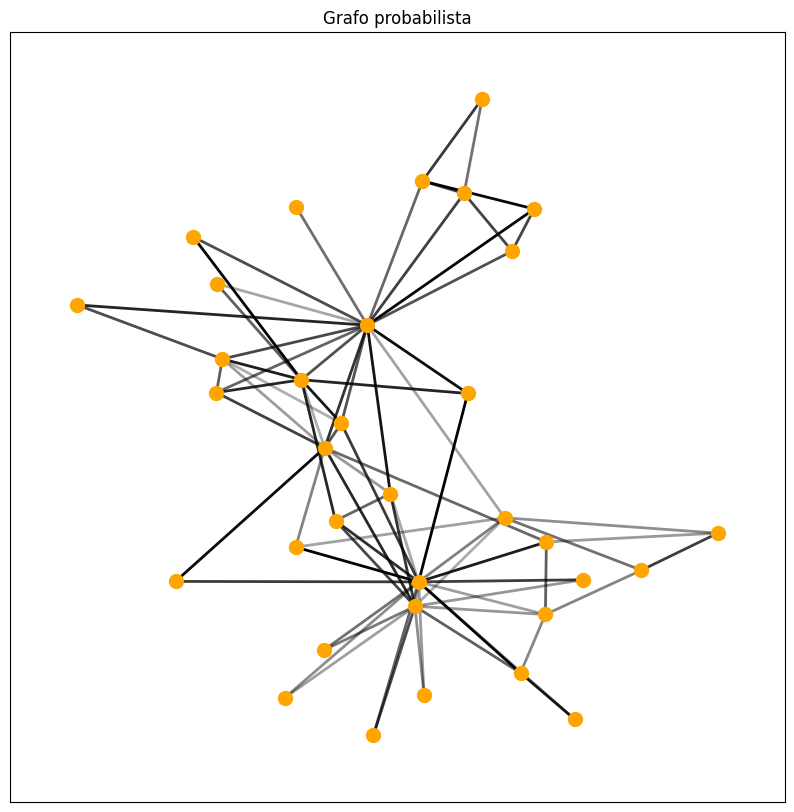

In [ ]:
pesos_aristas = [seed_G[u][v]["prob"] for u, v,data in seed_G.edges(data=True)]

plt.figure(figsize=(10, 10))
plt.title('Grafo probabilista, grafo 1')
nx.draw_networkx_nodes(seed_G,nx.spring_layout(seed_G, seed=42,k=0.14),node_color="orange",node_size=100)
nx.draw_networkx_edges(seed_G,nx.spring_layout(seed_G, seed=42,k=0.14),alpha=pesos_aristas,edge_color='black',width=2)
plt.show()

In [ ]:
# Ejecutar GraphGenerator con los parámetros recomendados en el paper
# (node_step = 5, w = 2/3, maxrej = 0.02·Em, intervalo E ± 2s)
synthetic_H, history_data = gpn.GraphGenerator(
    SAMPLE, ng, maxs=100000, node_step=20, w=2/3, maxrej=None, K=2, seed=0, verbose=2000
)

ÉXITO en el paso 438: n=22, m=35


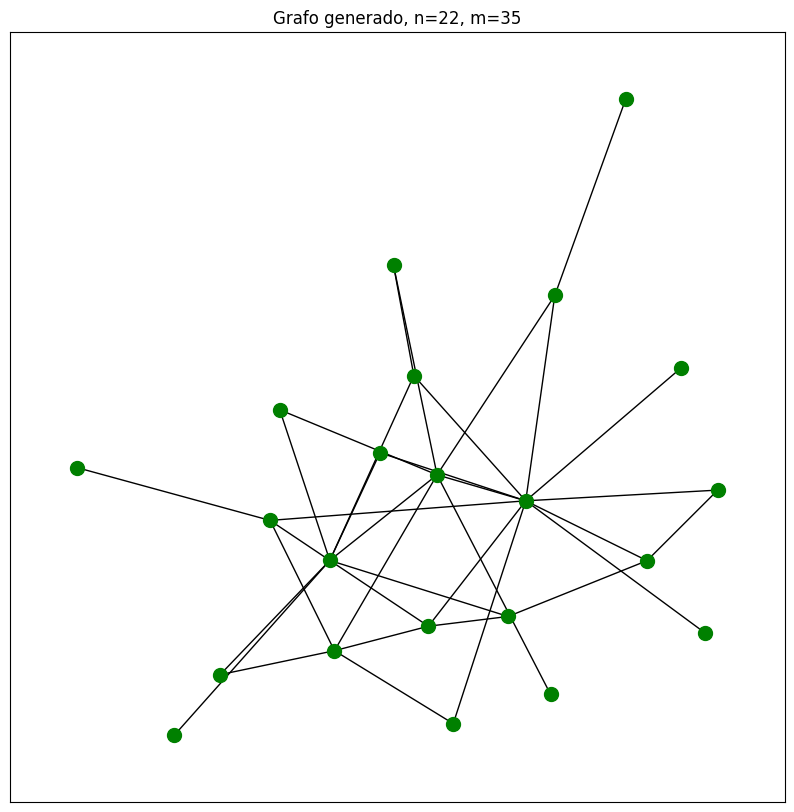

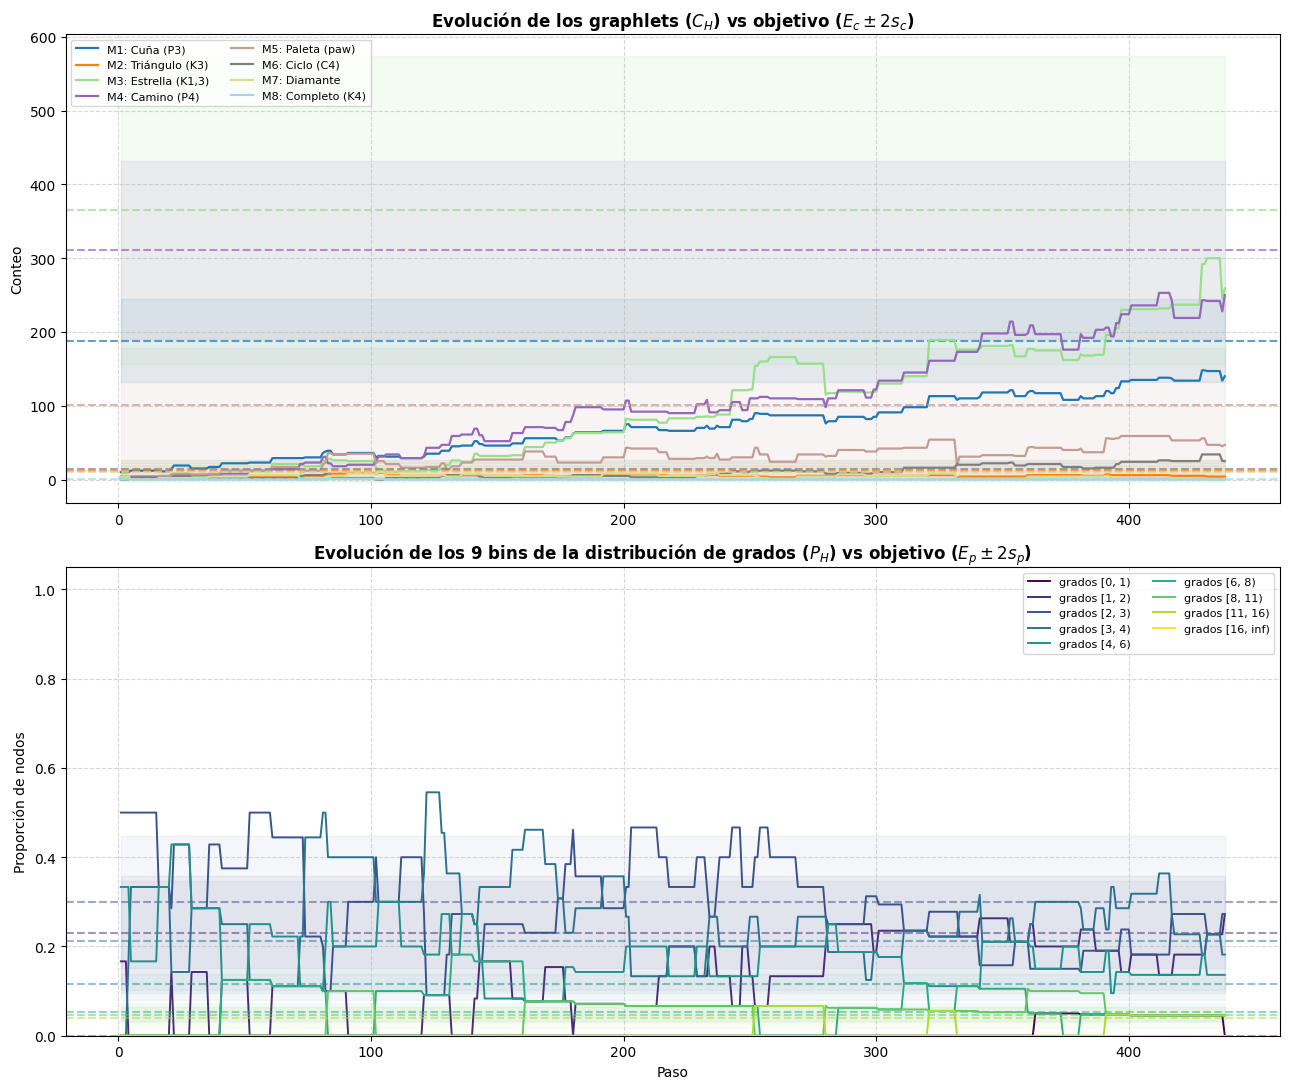

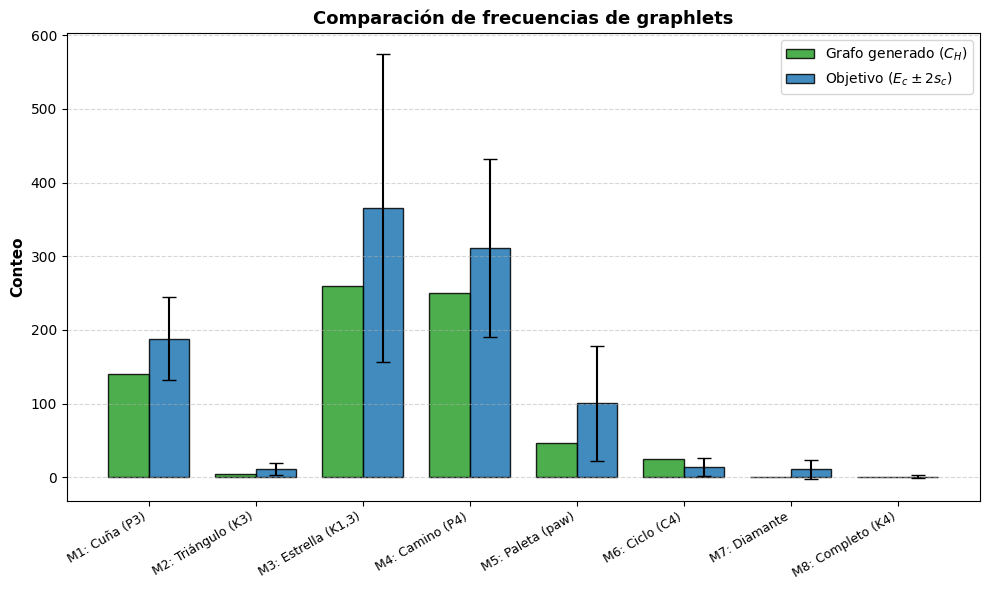

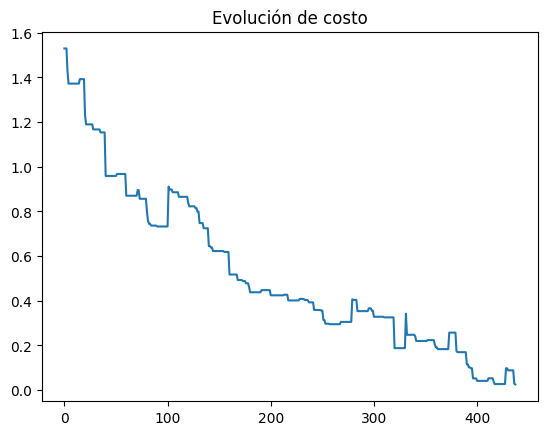

In [ ]:
n=history_data['n_trajectory'][-1]
m=history_data['m_trajectory'][-1]

plt.figure(figsize=(10, 10))
plt.title(f'Grafo generado, n={n}, m={m}')
nx.draw_networkx_nodes(synthetic_H,nx.spring_layout(synthetic_H, seed=42,k=0.14),node_color="green",node_size=100)
nx.draw_networkx_edges(synthetic_H,nx.spring_layout(synthetic_H, seed=42,k=0.14),edge_color='black',width=1)
plt.show()

gpn.plot_parameters_evolution(history_data)

final_CH_counts = history_data['CH_trajectory'][-1]
gpn.plot_graphlet_bar_comparison(final_CH_counts, history_data)
cost_evolution= history_data['cost_trajectory']
plt.title('Evolución de costo')
plt.plot(cost_evolution)

## PPI Cianobacterias

In [ ]:
# 3. Cárgalo de vuelta a NetworkX
G_cargado = nx.read_graphml('/content/grafo_proteinas_probabilista.graphml')
print(
    f"✨ ¡Grafo cargado exitosamente! Nodos: {G_cargado.number_of_nodes()},"
    f" Aristas: {G_cargado.number_of_edges()}"
)

✨ ¡Grafo cargado exitosamente! Nodos: 154, Aristas: 191


In [ ]:
MIMIN=min(nx.get_edge_attributes(G_cargado,'prob').values())
MIMAX=max(nx.get_edge_attributes(G_cargado,'prob').values())

# 1. Definir el umbral deseado
umbral = 0.1
lamb= 0.9
f=lambda x: lamb + (1-lamb)*x

# 2. Filtrar las aristas que cumplen la condición
# (Convertimos a float() por si acaso el grafo vino de GraphML como texto)
aristas_filtradas = [
    (u, v)
    for u, v, data in G_cargado.edges(data=True)
    if float(data.get("prob", 0.0)) >= umbral
]

# 3. Crear el nuevo subgrafo con esas aristas y sus nodos correspondientes
G_filtrado = G_cargado.edge_subgraph(aristas_filtradas).copy()

for u, v, data in G_filtrado.edges(data=True):
  # Ejemplo: multiplicar la probabilidad actual por 1.2
  prob_actual = float(data.get("prob", 0.0))

  # Aplicamos la operación matemática y la limitamos a un máximo de 1.0
  nuevo_peso = f(prob_actual)

  # Actualizamos el valor en la arista
  G_filtrado[u][v]["prob"] = nuevo_peso

print("¡Pesos actualizados con éxito!")

¡Pesos actualizados con éxito!


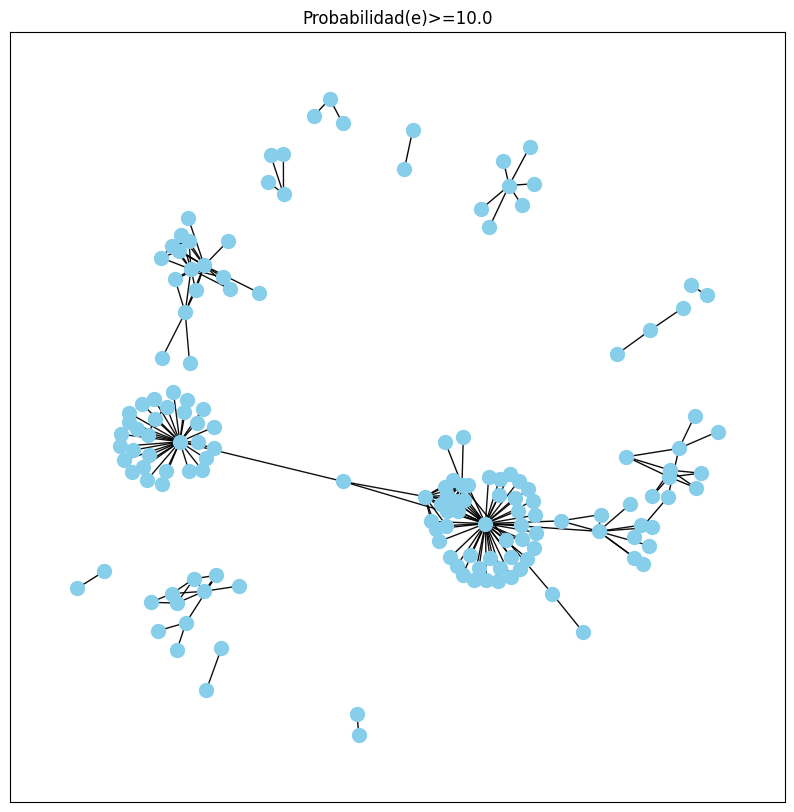

In [ ]:
pesos_aristas = [G_filtrado[u][v]["prob"] for u, v,data in G_filtrado.edges(data=True)]

plt.figure(figsize=(10, 10))
plt.title(f'Probabilidad(e)>={100*umbral}')
nx.draw_networkx_nodes(G_filtrado,nx.spring_layout(G_filtrado, seed=42,k=0.14),node_color="skyblue",node_size=100)
nx.draw_networkx_edges(G_filtrado,nx.spring_layout(G_filtrado, seed=42,k=0.14),alpha=pesos_aristas,edge_color='black')
plt.show()

In [ ]:
largest_component_nodes = max(nx.connected_components(G_filtrado), key=len)

# 2. Crear un subgrafo que contenga solo esos nodos
G_largest = G_filtrado.subgraph(largest_component_nodes).copy()

print(f"Número de nodos en el grafo original: {G_filtrado.number_of_nodes()}")
print(f"Número de nodos en la región más grande: {G_largest.number_of_nodes()}")

Número de nodos en el grafo original: 154
Número de nodos en la región más grande: 89


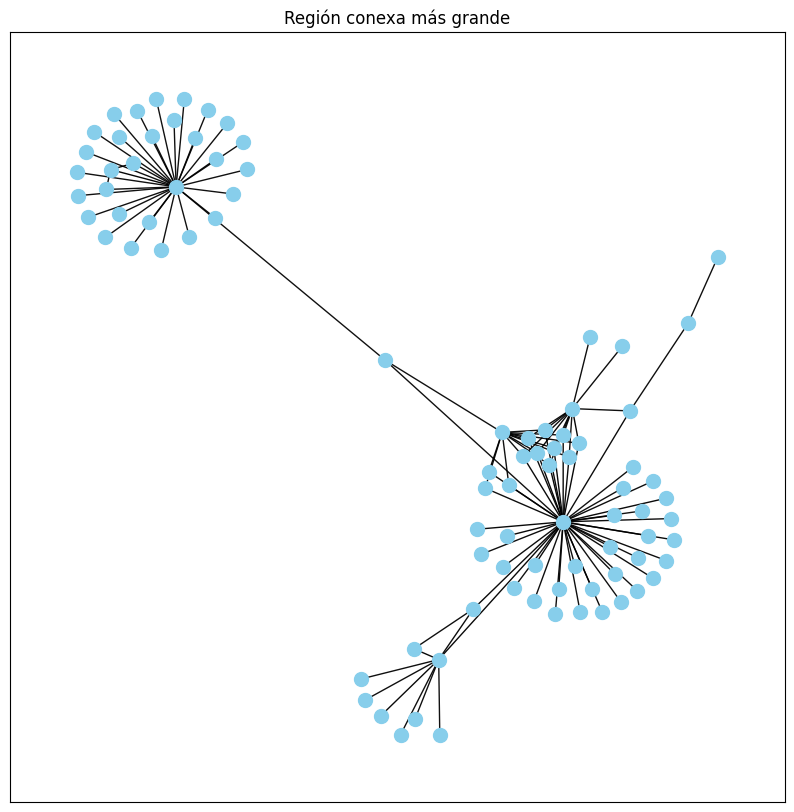

In [ ]:
pesos_aristas = [G_filtrado[u][v]["prob"] for u, v,data in G_largest.edges(data=True)]

plt.figure(figsize=(10, 10))
plt.title('Región conexa más grande')
nx.draw_networkx_nodes(G_largest,nx.spring_layout(G_largest, seed=42,k=0.14),node_color="skyblue",node_size=100)
nx.draw_networkx_edges(G_largest,nx.spring_layout(G_largest, seed=42,k=0.14),alpha=pesos_aristas,edge_color='black')
plt.show()

In [ ]:
G = G_largest
S = 1000     # el paper usa 10 000 muestras
ng = 4

SAMPLE = gpn.Sample(G, S, ng, seed=0)
print(f"En = {SAMPLE['En']:.2f} ± {SAMPLE['sn']:.2f}   Em = {SAMPLE['Em']:.2f} ± {SAMPLE['sm']:.2f}   CCg = {SAMPLE['CCg']:.3f}")
for nombre, e, s in zip(SAMPLE["cat"]["nombres"], SAMPLE["Ec"], SAMPLE["sc"]):
    print(f"  {nombre:18s} Ec = {e:8.1f}  ± 2sc = {2*s:7.1f}")

En = 82.97 ± 7.54   Em = 104.40 ± 8.24   CCg = 0.007
  Cuña (P3)          Ec =   1437.0  ± 2sc =   245.0
  Triángulo (K3)     Ec =      3.3  ± 2sc =     1.7
  Estrella (K1,3)    Ec =  15649.2  ± 2sc =  3081.6
  Camino (P4)        Ec =   1195.3  ± 2sc =   191.5
  Paleta (paw)       Ec =     86.3  ± 2sc =    47.1
  Ciclo (C4)         Ec =    128.0  ± 2sc =    40.9
  Diamante           Ec =      1.5  ± 2sc =     1.2
  Completo (K4)      Ec =      0.0  ± 2sc =     0.0


In [ ]:
# Ejecutar GraphGenerator con los parámetros recomendados en el paper
# (node_step = 5, w = 2/3, maxrej = 0.02·Em, intervalo E ± 2s)
synthetic_H, history_data = gpn.GraphGenerator(
    SAMPLE, ng, maxs=100000, node_step=5, w=0.9, maxrej=None, K=2, seed=0, verbose=2000
)

paso 2000: n=74, m=86, costo=0.1968
paso 4000: n=74, m=90, costo=0.1785
paso 6000: n=74, m=88, costo=0.1577
paso 8000: n=73, m=86, costo=0.1562
paso 10000: n=73, m=87, costo=0.1719
paso 12000: n=74, m=90, costo=0.1503
paso 14000: n=73, m=91, costo=0.1287
paso 16000: n=74, m=92, costo=0.1265
paso 18000: n=73, m=90, costo=0.1772
paso 20000: n=73, m=87, costo=0.1602
paso 22000: n=73, m=89, costo=0.1471
paso 24000: n=73, m=88, costo=0.1556
paso 26000: n=73, m=87, costo=0.1087
paso 28000: n=74, m=87, costo=0.1343
paso 30000: n=73, m=86, costo=0.1368
paso 32000: n=73, m=89, costo=0.0926
paso 34000: n=73, m=87, costo=0.0962
paso 36000: n=73, m=90, costo=0.1146
paso 38000: n=73, m=89, costo=0.0806
paso 40000: n=73, m=89, costo=0.1193
paso 42000: n=73, m=91, costo=0.1069
paso 44000: n=73, m=90, costo=0.0759
paso 46000: n=73, m=89, costo=0.0781
paso 48000: n=74, m=93, costo=0.0741
paso 50000: n=73, m=90, costo=0.0800
paso 52000: n=73, m=90, costo=0.0920
paso 54000: n=73, m=92, costo=0.0756
paso 

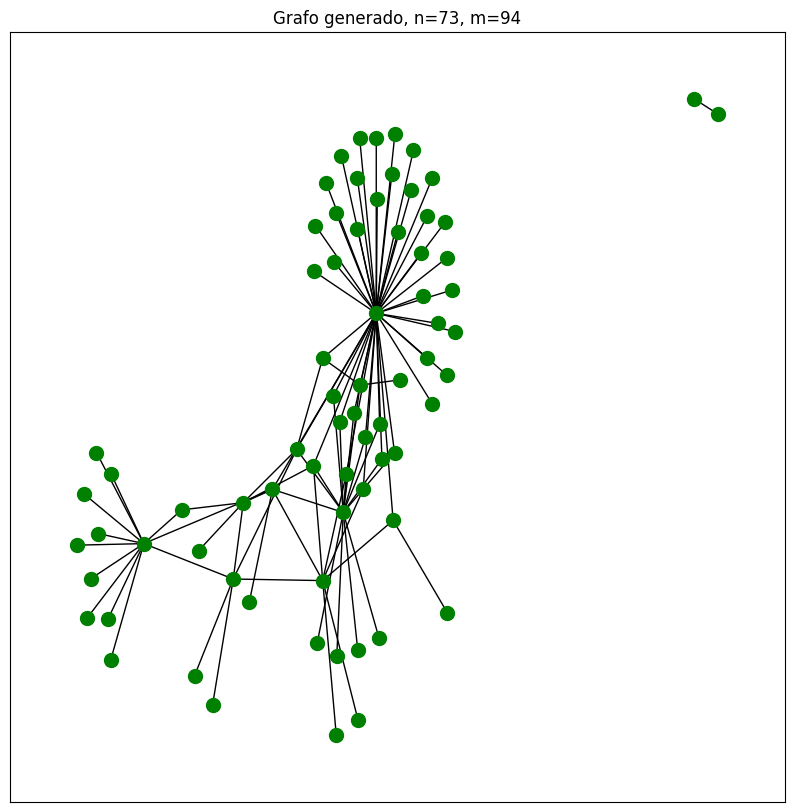

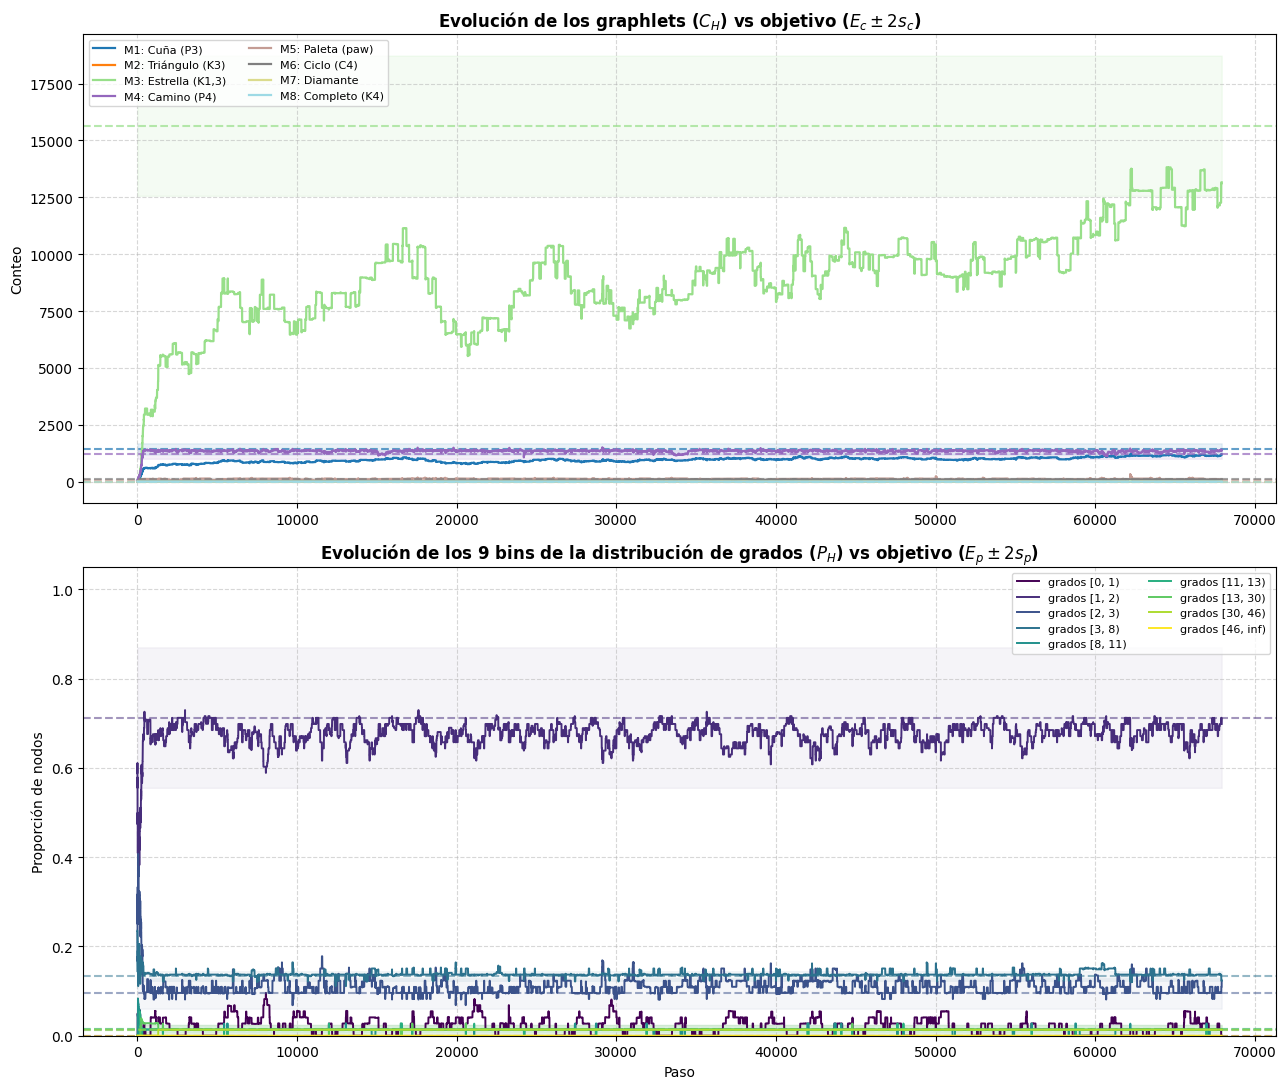

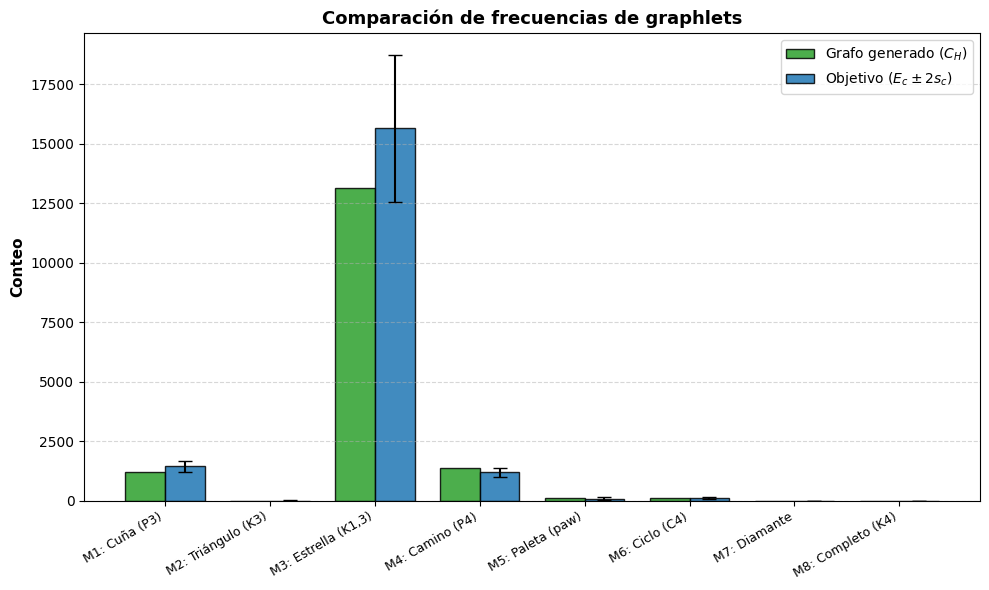

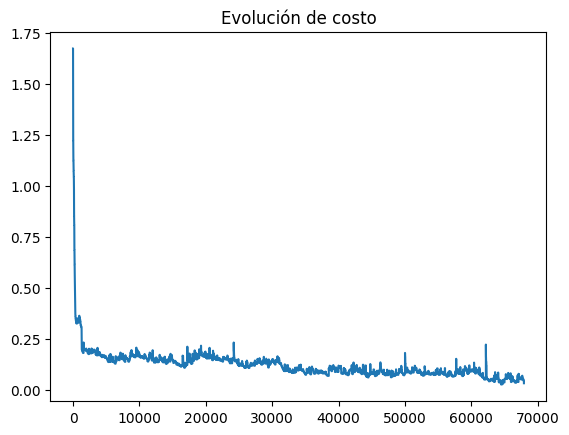

In [ ]:
n=history_data['n_trajectory'][-1]
m=history_data['m_trajectory'][-1]

plt.figure(figsize=(10, 10))
plt.title(f'Grafo generado, n={n}, m={m}')
nx.draw_networkx_nodes(synthetic_H,nx.spring_layout(synthetic_H, seed=42,k=0.14),node_color="green",node_size=100)
nx.draw_networkx_edges(synthetic_H,nx.spring_layout(synthetic_H, seed=42,k=0.14),edge_color='black',width=1)
plt.show()
gpn.plot_parameters_evolution(history_data)

final_CH_counts = history_data['CH_trajectory'][-1]
gpn.plot_graphlet_bar_comparison(final_CH_counts, history_data)
cost_evolution= history_data['cost_trajectory']
plt.title('Evolución de costo')
plt.plot(cost_evolution)

## PPI Humano

In [ ]:
# 3. Cárgalo de vuelta a NetworkX
G_core = nx.read_graphml('/content/grafo_proteinas_probabilista3.graphml')
print(
    f"✨ ¡Grafo cargado exitosamente! Nodos: {G_core.number_of_nodes()},"
    f" Aristas: {G_core.number_of_edges()}"
)

✨ ¡Grafo cargado exitosamente! Nodos: 799, Aristas: 3895


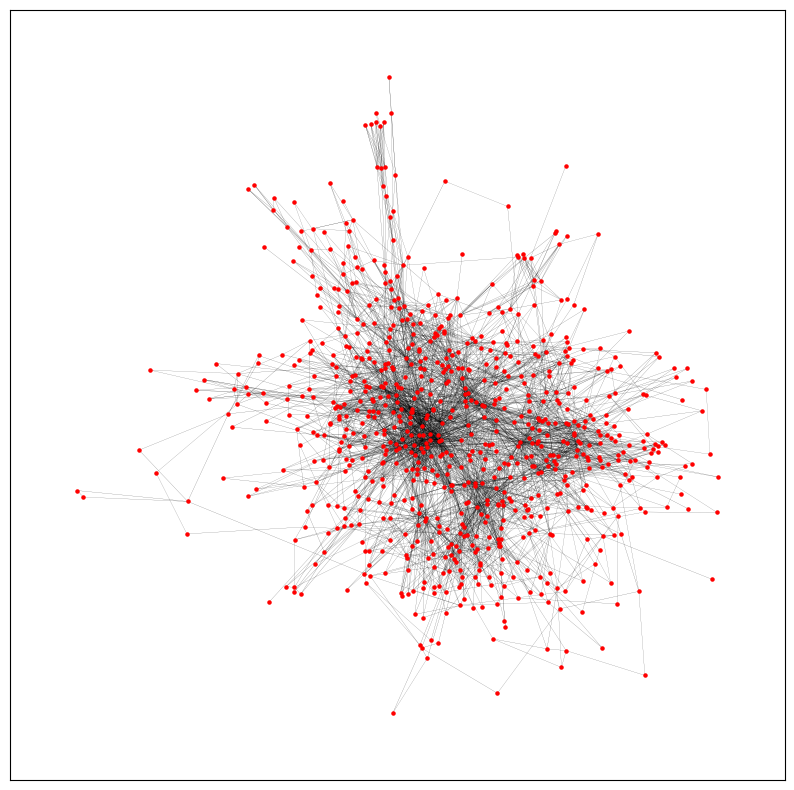

In [ ]:
pesos_aristas = [G_core[u][v]["prob"] for u, v,data in G_core.edges(data=True)]

plt.figure(figsize=(10, 10))
nx.draw_networkx_nodes(G_core,nx.spring_layout(G_core, seed=42,k=0.15),node_color="red",node_size=5)
nx.draw_networkx_edges(G_core,nx.spring_layout(G_core, seed=42,k=0.15),alpha=pesos_aristas,edge_color='black',width=0.1)
plt.show()

In [ ]:
G = G_core
S = 1000      # el paper usa 10 000 muestras
ng = 3

SAMPLE = gpn.Sample(G, S, ng, seed=0)
print(f"En = {SAMPLE['En']:.2f} ± {SAMPLE['sn']:.2f}   Em = {SAMPLE['Em']:.2f} ± {SAMPLE['sm']:.2f}   CCg = {SAMPLE['CCg']:.3f}")
for nombre, e, s in zip(SAMPLE["cat"]["nombres"], SAMPLE["Ec"], SAMPLE["sc"]):
    print(f"  {nombre:18s} Ec = {e:8.1f}  ± 2sc = {2*s:7.1f}")

En = 795.62 ± 1.85   Em = 3460.05 ± 19.70   CCg = 0.141
  Cuña (P3)          Ec =  55907.0  ± 2sc =  1399.6
  Triángulo (K3)     Ec =   3056.1  ± 2sc =   148.9


In [ ]:
# Ejecutar GraphGenerator con los parámetros recomendados en el paper
# (node_step = 5, w = 2/3, maxrej = 0.02·Em, intervalo E ± 2s)
synthetic_H, history_data = gpn.GraphGenerator(
    SAMPLE, ng, maxs=100000, node_step=100, w=2/3, maxrej=200, K=2, seed=0, verbose=2000
)

paso 2000: n=179, m=800, costo=19.3168
paso 4000: n=199, m=901, costo=17.4053
paso 6000: n=219, m=1005, costo=15.2032
paso 8000: n=239, m=1141, costo=12.3714
paso 10000: n=259, m=1261, costo=10.7658
paso 12000: n=279, m=1332, costo=10.0847
paso 14000: n=299, m=1430, costo=9.1355
paso 16000: n=319, m=1608, costo=6.9424
paso 18000: n=339, m=1697, costo=5.9081
paso 20000: n=359, m=1762, costo=5.2476
paso 22000: n=379, m=1838, costo=4.6177
paso 24000: n=398, m=1901, costo=4.1364
paso 26000: n=417, m=1972, costo=3.5781
paso 28000: n=437, m=2036, costo=3.1044
paso 30000: n=457, m=2108, costo=2.6726
paso 32000: n=476, m=2198, costo=2.1535
paso 34000: n=495, m=2258, costo=1.7145
paso 36000: n=510, m=2288, costo=1.5013
paso 38000: n=525, m=2348, costo=1.2799
paso 40000: n=541, m=2442, costo=0.8810
paso 42000: n=560, m=2506, costo=0.5842
paso 44000: n=577, m=2556, costo=0.2327
paso 46000: n=586, m=2586, costo=0.1881
paso 48000: n=601, m=2654, costo=0.1441
paso 50000: n=613, m=2712, costo=0.1223


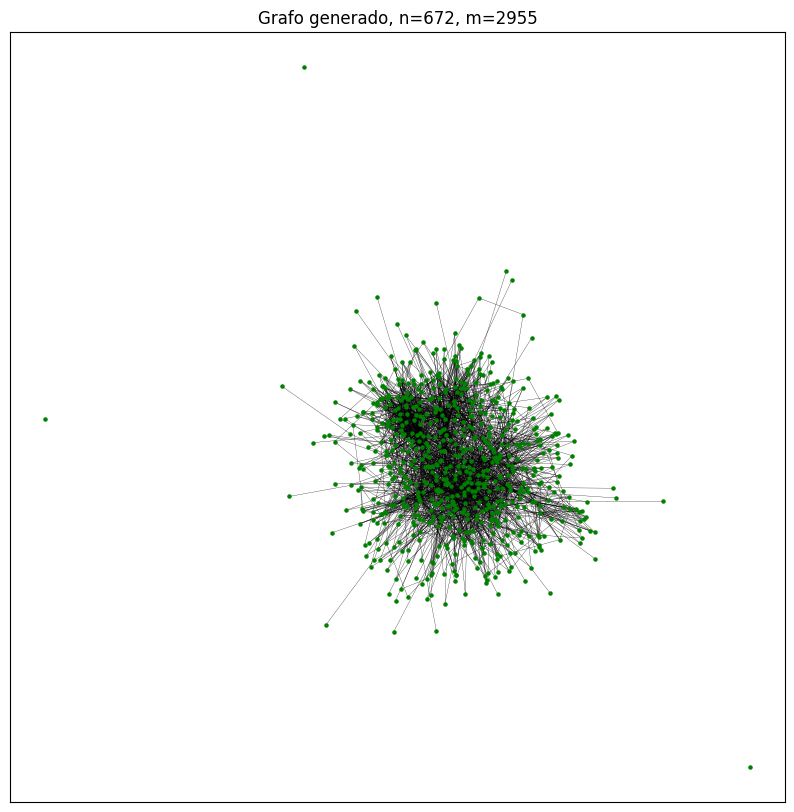

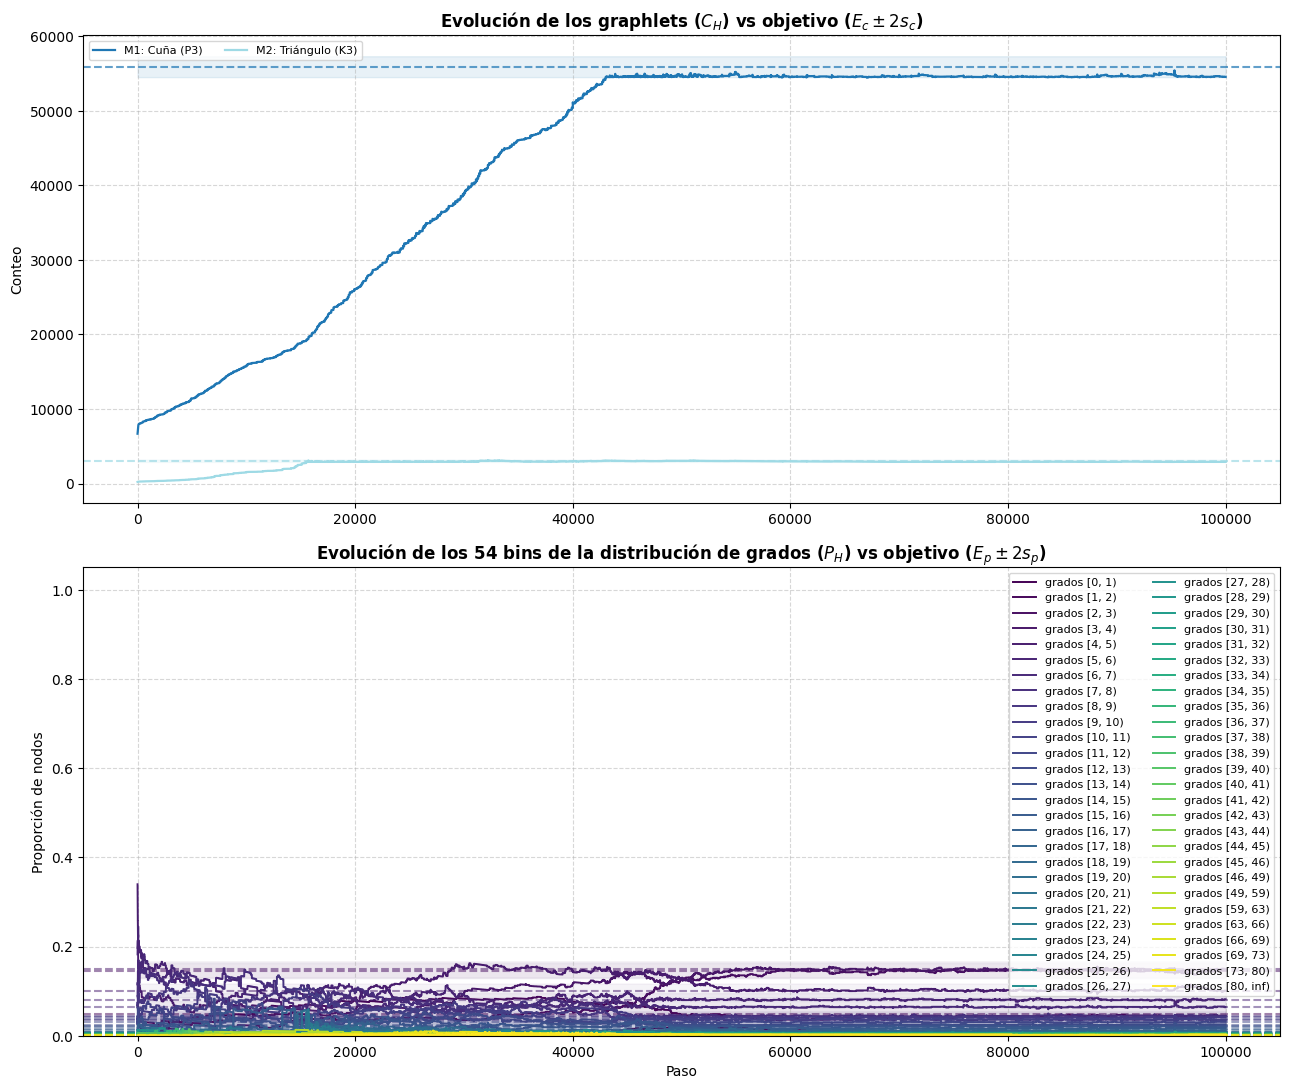

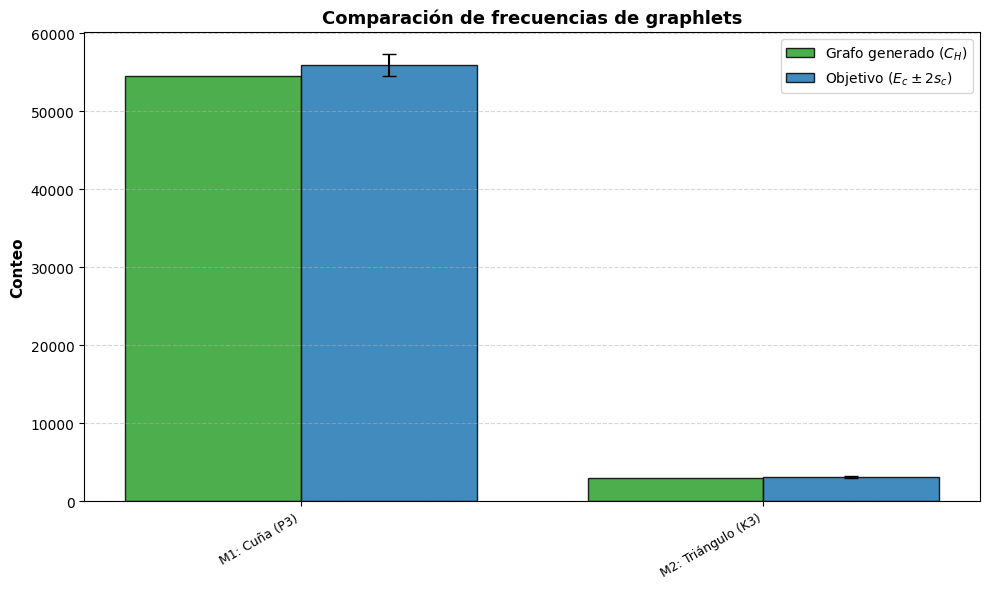

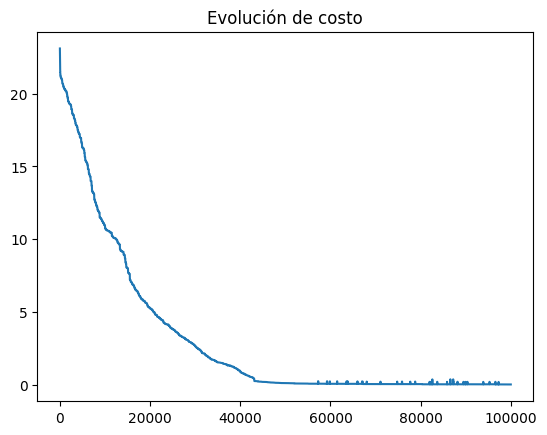

In [ ]:
n=history_data['n_trajectory'][-1]
m=history_data['m_trajectory'][-1]

plt.figure(figsize=(10, 10))
plt.title(f'Grafo generado, n={n}, m={m}')
nx.draw_networkx_nodes(synthetic_H,nx.spring_layout(synthetic_H, seed=42),node_color="green",node_size=5)
nx.draw_networkx_edges(synthetic_H,nx.spring_layout(synthetic_H, seed=42),edge_color='black',width=0.2)
plt.show()

gpn.plot_parameters_evolution(history_data)

final_CH_counts = history_data['CH_trajectory'][-1]
gpn.plot_graphlet_bar_comparison(final_CH_counts, history_data)
cost_evolution= history_data['cost_trajectory']
plt.title('Evolución de costo')
plt.plot(cost_evolution)

##PPI Coli

In [ ]:
# 3. Cárgalo de vuelta a NetworkX
G_core = nx.read_graphml('/content/grafo_proteinas_probabilista5.graphml')
print(
    f"✨ ¡Grafo cargado exitosamente! Nodos: {G_core.number_of_nodes()},"
    f" Aristas: {G_core.number_of_edges()}"
)

✨ ¡Grafo cargado exitosamente! Nodos: 484, Aristas: 664


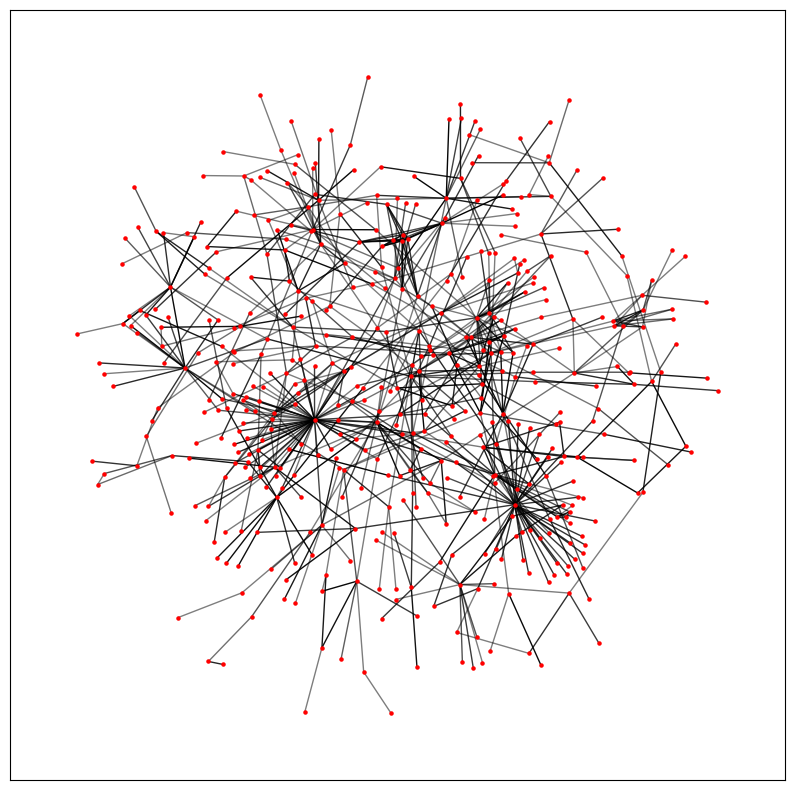

In [ ]:
pesos_aristas = [G_core[u][v]["prob"] for u, v,data in G_core.edges(data=True)]

plt.figure(figsize=(10, 10))
nx.draw_networkx_nodes(G_core,nx.spring_layout(G_core, seed=42,k=0.15),node_color="red",node_size=5)
nx.draw_networkx_edges(G_core,nx.spring_layout(G_core, seed=42,k=0.15),alpha=pesos_aristas,edge_color='black',width=1)
plt.show()

In [ ]:
G = G_core
S = 1000      # el paper usa 10 000 muestras
ng = 3

SAMPLE = gpn.Sample(G, S, ng, seed=0)
print(f"En = {SAMPLE['En']:.2f} ± {SAMPLE['sn']:.2f}   Em = {SAMPLE['Em']:.2f} ± {SAMPLE['sm']:.2f}   CCg = {SAMPLE['CCg']:.3f}")
for nombre, e, s in zip(SAMPLE["cat"]["nombres"], SAMPLE["Ec"], SAMPLE["sc"]):
    print(f"  {nombre:18s} Ec = {e:8.1f}  ± 2sc = {2*s:7.1f}")

En = 321.66 ± 20.71   Em = 397.85 ± 24.19   CCg = 0.062
  Cuña (P3)          Ec =   2094.7  ± 2sc =   448.9
  Triángulo (K3)     Ec =     46.4  ± 2sc =    16.1


In [ ]:
# Ejecutar GraphGenerator con los parámetros recomendados en el paper
# (node_step = 5, w = 2/3, maxrej = 0.02·Em, intervalo E ± 2s)
synthetic_H, history_data = gpn.GraphGenerator(
    SAMPLE, ng, maxs=200000, node_step=100, w=2/3, maxrej=200, K=2, seed=0, verbose=2000
)

paso 2000: n=84, m=138, costo=1.5148
paso 4000: n=104, m=168, costo=1.0742
paso 6000: n=123, m=196, costo=0.9618
paso 8000: n=139, m=217, costo=0.8196
paso 10000: n=153, m=247, costo=0.7286
paso 12000: n=169, m=276, costo=0.6759
paso 14000: n=187, m=300, costo=0.5841
paso 16000: n=203, m=323, costo=0.5073
paso 18000: n=216, m=350, costo=0.4714
paso 20000: n=234, m=376, costo=0.3988
paso 22000: n=245, m=372, costo=0.1998
paso 24000: n=254, m=368, costo=0.1853
paso 26000: n=259, m=360, costo=0.1643
paso 28000: n=267, m=350, costo=0.1135
paso 30000: n=278, m=343, costo=0.0746
paso 32000: n=284, m=346, costo=0.0192
paso 34000: n=284, m=346, costo=0.0193
paso 36000: n=284, m=346, costo=0.0599
paso 38000: n=285, m=342, costo=0.0204
paso 40000: n=285, m=346, costo=0.0195
paso 42000: n=285, m=342, costo=0.0214
paso 44000: n=288, m=348, costo=0.0200
paso 46000: n=288, m=352, costo=0.0192
paso 48000: n=293, m=357, costo=0.0167
paso 50000: n=295, m=358, costo=0.0161
ÉXITO en el paso 51203: n=298,

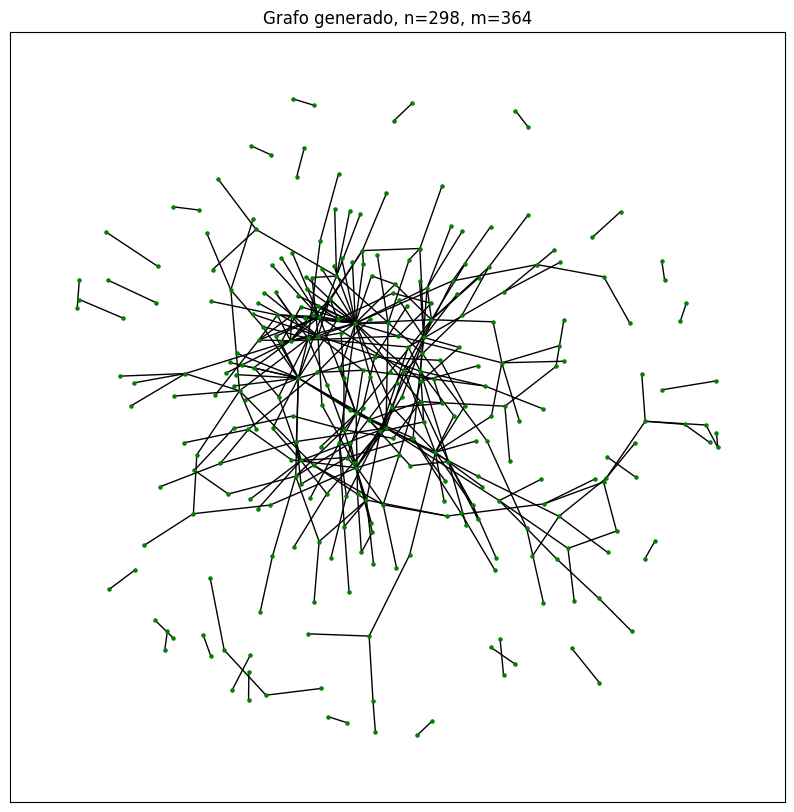

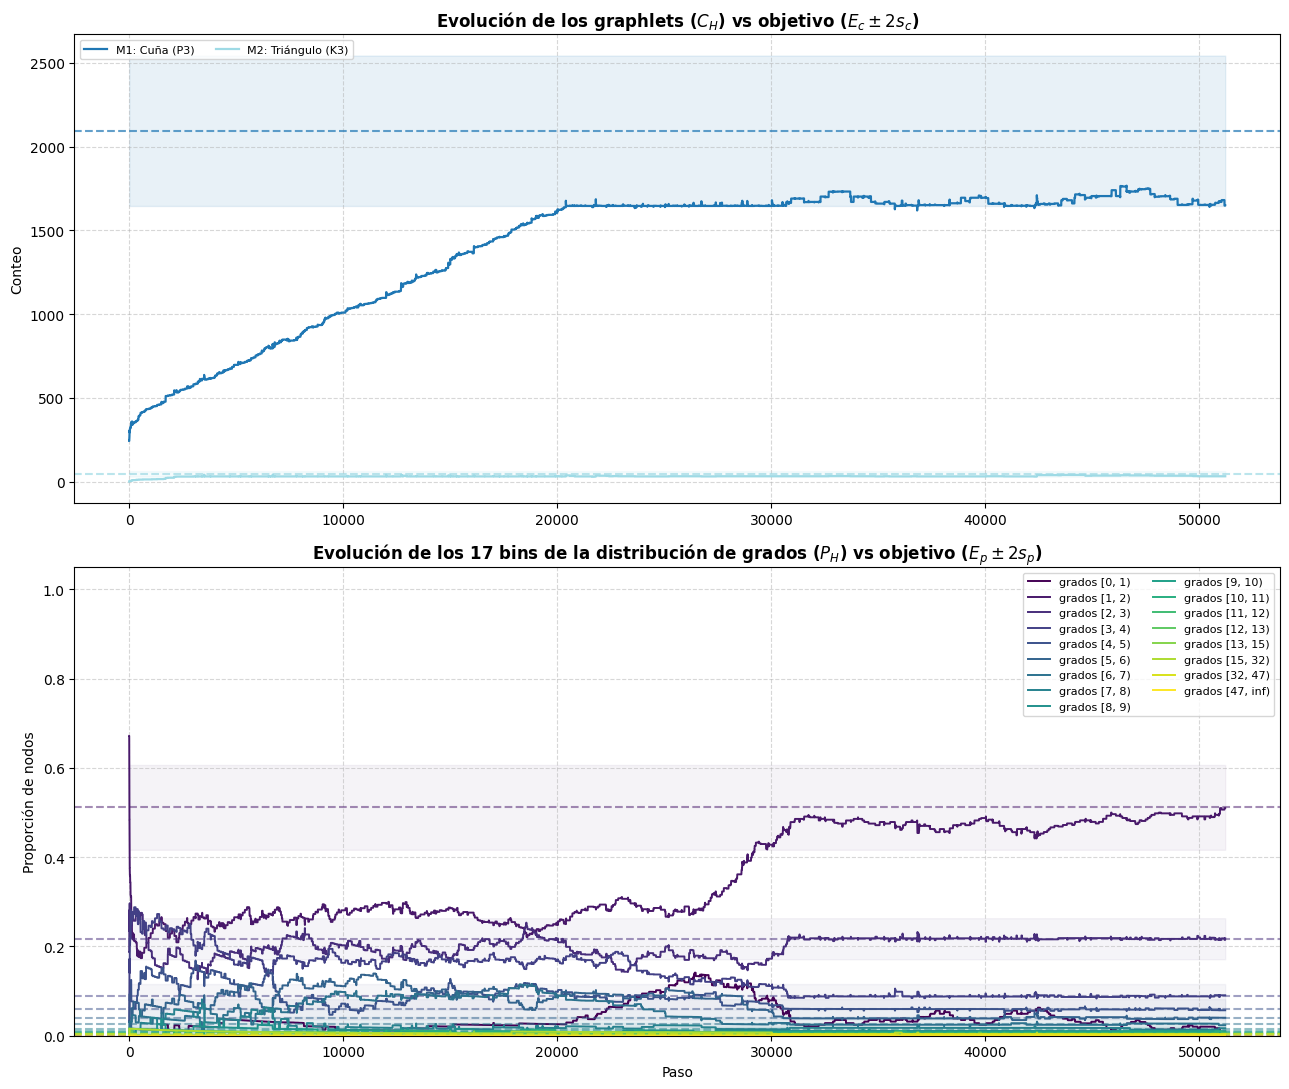

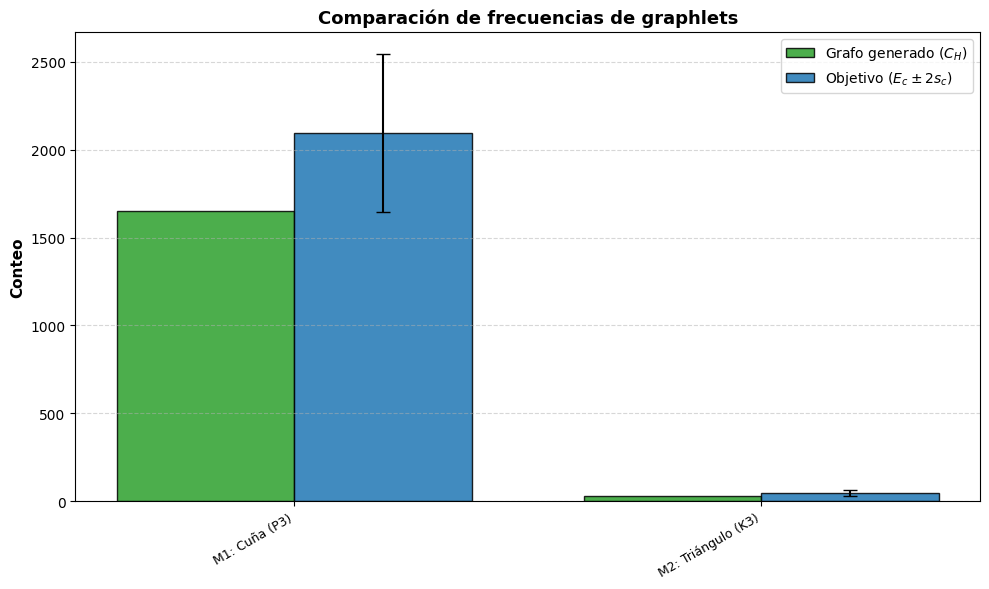

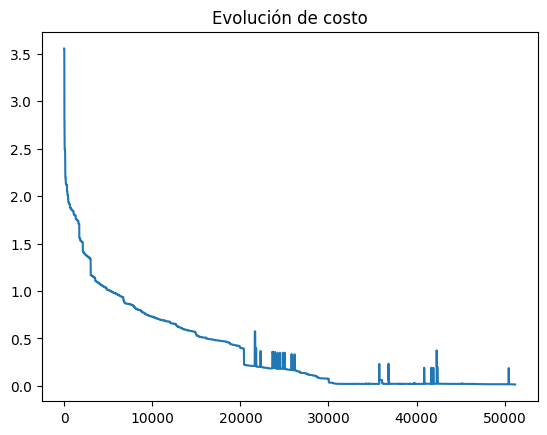

In [ ]:
n=history_data['n_trajectory'][-1]
m=history_data['m_trajectory'][-1]

plt.figure(figsize=(10, 10))
plt.title(f'Grafo generado, n={n}, m={m}')
nx.draw_networkx_nodes(synthetic_H,nx.spring_layout(synthetic_H, seed=42,k=0.15),node_color="green",node_size=5)
nx.draw_networkx_edges(synthetic_H,nx.spring_layout(synthetic_H, seed=42,k=0.15),edge_color='black',width=0.5)
plt.show()

gpn.plot_parameters_evolution(history_data)

final_CH_counts = history_data['CH_trajectory'][-1]
gpn.plot_graphlet_bar_comparison(final_CH_counts, history_data)
cost_evolution= history_data['cost_trajectory']
plt.title('Evolución de costo')
plt.plot(cost_evolution)

## PPI nautili

In [ ]:
# 3. Cárgalo de vuelta a NetworkX
G_core = nx.read_graphml('/content/grafo_proteinas_probabilista7.graphml')
print(
    f"✨ ¡Grafo cargado exitosamente! Nodos: {G_core.number_of_nodes()},"
    f" Aristas: {G_core.number_of_edges()}"
)

✨ ¡Grafo cargado exitosamente! Nodos: 275, Aristas: 775


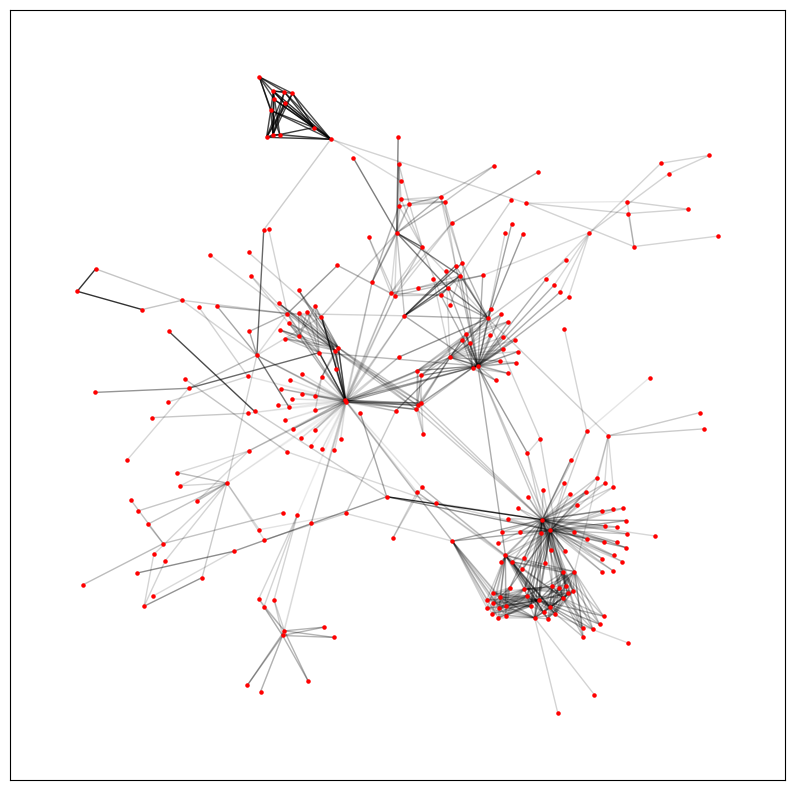

In [ ]:
pesos_aristas = [G_core[u][v]["prob"] for u, v,data in G_core.edges(data=True)]

plt.figure(figsize=(10, 10))
nx.draw_networkx_nodes(G_core,nx.spring_layout(G_core, seed=42,k=0.15),node_color="red",node_size=5)
nx.draw_networkx_edges(G_core,nx.spring_layout(G_core, seed=42,k=0.15),alpha=pesos_aristas,edge_color='black',width=1)
plt.show()

In [ ]:
G = G_core
S = 1000      # el paper usa 10 000 muestras
ng = 4

SAMPLE = gpn.Sample(G, S, ng, seed=0)
print(f"En = {SAMPLE['En']:.2f} ± {SAMPLE['sn']:.2f}   Em = {SAMPLE['Em']:.2f} ± {SAMPLE['sm']:.2f}   CCg = {SAMPLE['CCg']:.3f}")
for nombre, e, s in zip(SAMPLE["cat"]["nombres"], SAMPLE["Ec"], SAMPLE["sc"]):
    print(f"  {nombre:18s} Ec = {e:8.1f}  ± 2sc = {2*s:7.1f}")

En = 109.25 ± 19.86   Em = 142.16 ± 28.50   CCg = 0.033
  Cuña (P3)          Ec =    603.9  ± 2sc =   316.1
  Triángulo (K3)     Ec =      6.9  ± 2sc =     9.2
  Estrella (K1,3)    Ec =   1727.1  ± 2sc =  1435.3
  Camino (P4)        Ec =   1331.5  ± 2sc =   880.7
  Paleta (paw)       Ec =     90.6  ± 2sc =   111.4
  Ciclo (C4)         Ec =     32.2  ± 2sc =    39.0
  Diamante           Ec =      3.9  ± 2sc =    12.9
  Completo (K4)      Ec =      0.1  ± 2sc =     0.9


In [ ]:
# Ejecutar GraphGenerator con los parámetros recomendados en el paper
# (node_step = 5, w = 2/3, maxrej = 0.02·Em, intervalo E ± 2s)
synthetic_H, history_data = gpn.GraphGenerator(
    SAMPLE, ng, maxs=200000, node_step=100, w=2/3, maxrej=200, K=2, seed=0, verbose=2000
)

paso 2000: n=33, m=44, costo=0.2214
paso 4000: n=46, m=61, costo=0.0983
paso 6000: n=46, m=61, costo=0.0855
paso 8000: n=47, m=61, costo=0.0802
paso 10000: n=48, m=63, costo=0.0816
paso 12000: n=48, m=63, costo=0.0806
paso 14000: n=48, m=63, costo=0.0806
paso 16000: n=47, m=62, costo=0.0788
paso 18000: n=50, m=66, costo=0.0767
paso 20000: n=53, m=70, costo=0.0664
paso 22000: n=63, m=80, costo=0.0410
paso 24000: n=63, m=81, costo=0.0413
paso 26000: n=63, m=81, costo=0.0410
paso 28000: n=63, m=81, costo=0.0413
paso 30000: n=63, m=82, costo=0.0413
paso 32000: n=63, m=81, costo=0.0421
paso 34000: n=64, m=82, costo=0.0420
ÉXITO en el paso 34603: n=64, m=83


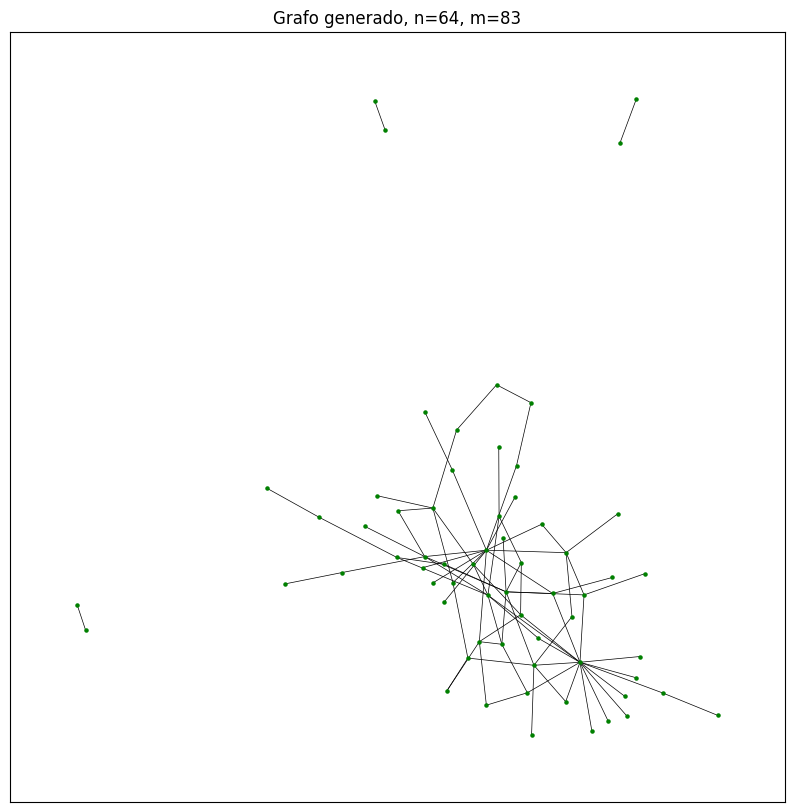

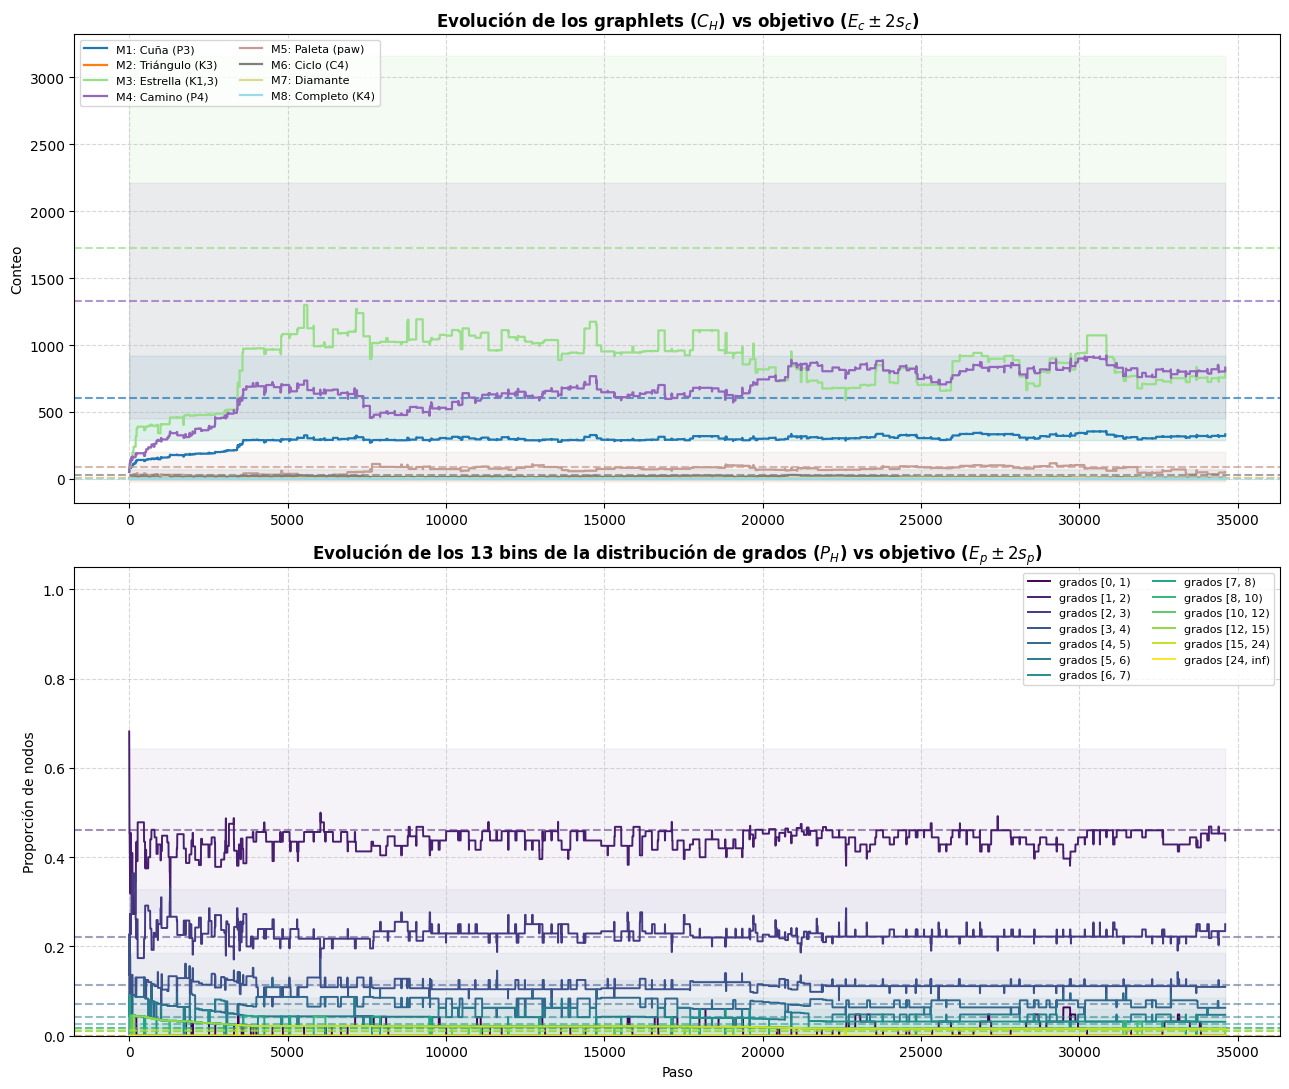

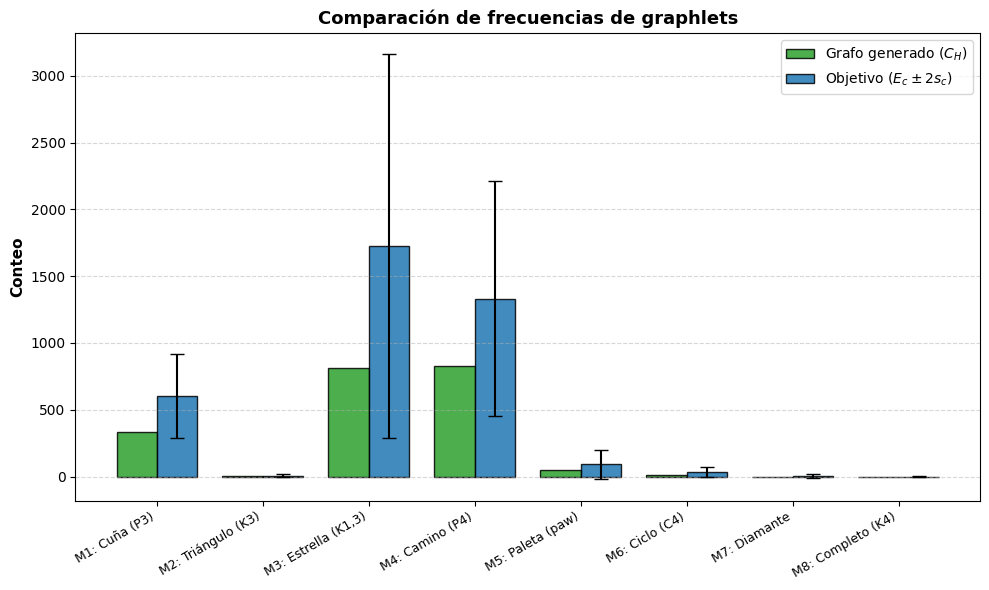

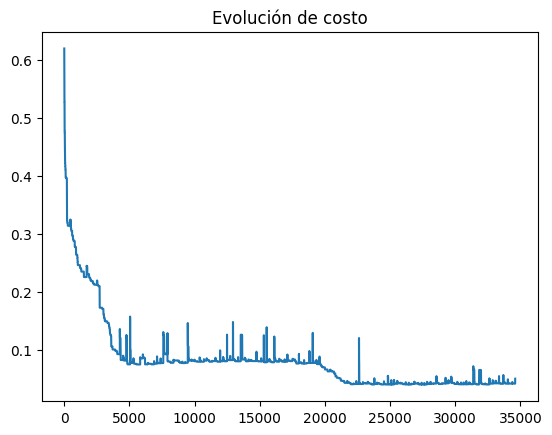

In [ ]:
n=history_data['n_trajectory'][-1]
m=history_data['m_trajectory'][-1]

plt.figure(figsize=(10, 10))
plt.title(f'Grafo generado, n={n}, m={m}')
nx.draw_networkx_nodes(synthetic_H,nx.spring_layout(synthetic_H, seed=42,k=0.15),node_color="green",node_size=5)
nx.draw_networkx_edges(synthetic_H,nx.spring_layout(synthetic_H, seed=42,k=0.15),edge_color='black',width=0.5)
plt.show()

gpn.plot_parameters_evolution(history_data)

final_CH_counts = history_data['CH_trajectory'][-1]
gpn.plot_graphlet_bar_comparison(final_CH_counts, history_data)
cost_evolution= history_data['cost_trajectory']
plt.title('Evolución de costo')
plt.plot(cost_evolution)

## tiempos

In [35]:
import time

def GraphGeneratorT(SAMPLE, ng=None, maxs=10000, node_step=5, w=2/3, maxrej=None, K=2,
                   seed=None, verbose=1000):
    """
    Algorithm 1: generador incremental GRAIP.
    SAMPLE: resultado de Sample(G, S, ng).  K = 2 corresponde al intervalo [E-2s, E+2s] del paper.
    """
    cat = SAMPLE["cat"]
    if ng is not None and ng != cat["ng"]:
        raise ValueError("ng no coincide con el usado en Sample")
    if seed is not None:
        random.seed(seed)
        np.random.seed(seed)

    En, sn, Em, sm = SAMPLE["En"], SAMPLE["sn"], SAMPLE["Em"], SAMPLE["sm"]
    Ec = np.asarray(SAMPLE["Ec"], dtype=float)
    sc = np.asarray(SAMPLE["sc"], dtype=float)
    CCg = SAMPLE["CCg"]
    bins, Ep, sp = gpn.objetivos_grado(SAMPLE)
    if maxrej is None:
        maxrej = max(10, int(round(0.02 * Em)))

    # Semilla: grafo BA con ~20% de los nodos y de las aristas.
    # OJO: el parámetro m de barabasi_albert_graph es "aristas por nodo nuevo", no el total.
    n0 = max(3, int(round(En / 5)))
    m0 = max(1, int(round(Em / 5)))
    m_ba = max(1, min(n0 - 1, int(round(m0 / n0))))
    H = nx.barabasi_albert_graph(n0, m_ba, seed=seed)
    proximo_id = n0

    def proporciones(Gr):
        return gpn.Histogram([d for _, d in Gr.degree()], bins) / max(Gr.number_of_nodes(), 1)

    PH = proporciones(H)
    CH = gpn.contar_graphlets(H, cat)
    costH = gpn.Cost(PH, CH, Ep, sp, Ec, sc, w, En)
    rechazos = 0

    history = {
        'steps': [], 'CH_trajectory': [], 'PG_hist_trajectory': [],
        'n_trajectory': [], 'm_trajectory': [], 'cost_trajectory': [],
        'Ep': Ep, 'sp': sp, 'Ec': Ec, 'sc': sc, 'bins': bins, 'K': K,
        'nombres': cat['nombres'], 'exito': False,
    }

    def registrar(paso):
        history['steps'].append(paso)
        history['CH_trajectory'].append(CH.tolist())
        history['PG_hist_trajectory'].append(PH.tolist())
        history['n_trajectory'].append(H.number_of_nodes())
        history['m_trajectory'].append(H.number_of_edges())
        history['cost_trajectory'].append(costH)

    T=[]
    for step in range(1, maxs + 1):
        if step>1:
          tf=time.perf_counter()
          T.append(tf-t0)
        t0=time.perf_counter()
        registrar(step)
        if gpn.dentro_de_limites(PH, CH, Ep, sp, Ec, sc, K):
            history['exito'] = True
            print(f'ÉXITO en el paso {step}: n={H.number_of_nodes()}, m={H.number_of_edges()}')
            return H, history,np.mean(np.array(T))

        n = H.number_of_nodes()
        m = H.number_of_edges()
        r = random.random()
        accion = None
        if step % node_step == 0:
            if r > gpn._f_logistica(n, En, sn):                       # agregar nodo
                accion = ("add_node", (proximo_id, gpn.AddNode(H, CCg, proximo_id)))
            elif n > 3:                                           # quitar nodo
                u = random.choice(list(H.nodes()))
                accion = ("remove_node", (u, list(H.adj[u])))
        else:
            m_escalado = m * En / n if n > 0 else 0.0             # m escalado por En/n (paper)
            if r > gpn._f_logistica(m_escalado, Em, sm):              # agregar arista
                par = gpn.arista_ausente_al_azar(H)
                if par is not None:
                    accion = ("add_edge", par)
            elif m > 0:                                           # quitar arista
                accion = ("remove_edge", random.choice(list(H.edges())))
        if accion is None:
            continue

        dC = gpn.aplicar_cambio(H, accion, cat)
        CT = CH + dC
        PT = proporciones(H)
        costT = gpn.Cost(PT, CT, Ep, sp, Ec, sc, w, En)

        if costT < costH or rechazos >= maxrej:
            CH, PH, costH = CT, PT, costT
            rechazos = 0
            if accion[0] == "add_node":
                proximo_id += 1
        else:
            gpn.deshacer_cambio(H, accion)
            rechazos += 1

        if verbose and step % verbose == 0:
            print(f'paso {step}: n={H.number_of_nodes()}, m={H.number_of_edges()}, costo={costH:.4f}')

    registrar(maxs + 1)
    print(f'No convergió en {maxs} pasos (costo final {costH:.4f}).')
    return H, history, np.mean(np.array(T))

In [100]:
import networkx as nx
import random

def generar_grafo_conexo_aleatorio(n, m, seed=None):
    """
    Genera un grafo no dirigido, conexo, con n nodos, m aristas
    y pesos uniformes en [0, 1].
    """
    if seed is not None:
        random.seed(seed)

    min_edges = n - 1
    max_edges = n * (n - 1) // 2

    # Validar que el número de aristas sea lógicamente posible para un grafo conexo
    if not (min_edges <= m <= max_edges):
        raise ValueError(f"Para {n} nodos, m debe estar entre {min_edges} y {max_edges}.")

    G = nx.Graph()
    nodes = list(range(n))
    G.add_nodes_from(nodes)

    # PASO 1: Garantizar conectividad creando un árbol aleatorio (n - 1 aristas)
    # Mezclamos los nodos para que la estructura sea aleatoria
    shuffled_nodes = nodes.copy()
    random.shuffle(shuffled_nodes)

    for i in range(1, n):
        # Conectar cada nodo a un nodo anterior ya seleccionado al azar
        prev_node = random.choice(shuffled_nodes[:i])
        current_node = shuffled_nodes[i]
        G.add_edge(current_node, prev_node)

    # PASO 2: Agregar las aristas faltantes al azar entre pares que no estén conectados
    aristas_faltantes = m - (n - 1)
    if aristas_faltantes > 0:
        # Encontrar todas las posibles aristas que aún no existen
        posibles_aristas = []
        for i in range(n):
            for j in range(i + 1, n):
                if not G.has_edge(nodes[i], nodes[j]):
                    posibles_aristas.append((nodes[i], nodes[j]))

        # Seleccionar aleatoriamente las aristas que faltan
        aristas_a_agregar = random.sample(posibles_aristas, aristas_faltantes)
        G.add_edges_from(aristas_a_agregar)

    # PASO 3: Asignar pesos aleatorios uniformes [0, 1] a cada arista
    for u, v in G.edges():
        G[u][v]['prob'] = random.uniform(0.0, 1.0)

    return G

# --- Ejemplo de uso ---
n_nodos = 10
m_aristas = 18

G_conexo = generar_grafo_conexo_aleatorio(n=n_nodos, m=m_aristas, seed=42)

print(f"¿Es conexo?: {nx.is_connected(G_conexo)}")
print(f"Número de nodos: {G_conexo.number_of_nodes()}")
print(f"Número de aristas: {G_conexo.number_of_edges()}")

# Mostrar algunas aristas con sus respectivos pesos aleatorios
print("\nEjemplo de aristas y sus pesos:")
for u, v, data in list(G_conexo.edges(data=True))[:5]:
    print(f"Arista ({u} <-> {v}): peso = {data['prob']:.4f}")

¿Es conexo?: True
Número de nodos: 10
Número de aristas: 18

Ejemplo de aristas y sus pesos:
Arista (0 <-> 7): peso = 0.0065
Arista (0 <-> 1): peso = 0.8058
Arista (1 <-> 7): peso = 0.6981
Arista (1 <-> 9): peso = 0.3403
Arista (1 <-> 3): peso = 0.1555


In [101]:
import networkx as nx
import random

# Definir el rango de 20 a 200 en intervalos de 20
rangos = range(20, 5001, 1000)  # [20, 40, 60, 80, 100, 120, 140, 160, 180, 200]

catalogo_paralelo = {}

print("--- GENERANDO CATÁLOGO EN PARALELO (n = m de 20 a 200) ---\n")

for val in rangos:
    n = val
    m = val  # n y m toman el mismo valor simultáneamente

    min_edges = n - 1
    max_edges = n * (n - 1) // 2

    # Validar que el valor cumpla con las restricciones de un grafo conexo
    if min_edges <= m <= max_edges:
        try:
            # Asumiendo que tienes definida tu función generar_grafo_conexo_aleatorio previamente
            G = generar_grafo_conexo_aleatorio(n, m=m, seed=42)

            # Guardamos usando n (o una tupla si lo prefieres) como clave del diccionario
            catalogo_paralelo[n] = G
            print(f"✅ Generado -> n: {n:3d} | m: {m:3d} (Conexo: {nx.is_connected(G)})")
        except Exception as e:
            print(f"⚠️ Error para n={n}, m={m} -> {e}")
    else:
        print(f"❌ Inválido  -> n: {n:3d} | m: {m:3d} (Fuera de rango [{min_edges}, {max_edges}])")

print(f"\n¡Catálogo completado! Se generaron {len(catalogo_paralelo)} grafos válidos en total.")

--- GENERANDO CATÁLOGO EN PARALELO (n = m de 20 a 200) ---

✅ Generado -> n:  20 | m:  20 (Conexo: True)
✅ Generado -> n: 1020 | m: 1020 (Conexo: True)
✅ Generado -> n: 2020 | m: 2020 (Conexo: True)
✅ Generado -> n: 3020 | m: 3020 (Conexo: True)
✅ Generado -> n: 4020 | m: 4020 (Conexo: True)

¡Catálogo completado! Se generaron 5 grafos válidos en total.


In [110]:
import networkx as nx
import numpy as np

# Asegúrate de que 'catalogo_paralelo' y 'gpn' ya estén definidos y cargados en tu entorno
catalogo_samples = {}
ng_valor = 5
S_muestras = 1000  # Puedes ajustarlo a 10000 si lo requieres

print(f"--- GENERANDO CATÁLOGO DE SAMPLES DESDE EL CATÁLOGO BASE (ng={ng_valor}, S={S_muestras}) ---\n")

for n, G_seed in catalogo_paralelo.items():
    try:
        # 1. Ejecutar gpn.Sample utilizando el grafo semilla ya existente en el catálogo
        SAMPLE = gpn.Sample(G_seed, S=S_muestras, ng=ng_valor, seed=42)

        # 2. Guardar los resultados en el nuevo catálogo de samples
        catalogo_samples[n] = {
            'n': n,
            'm': G_seed.number_of_edges(),
            'SAMPLE': SAMPLE,
            'En': SAMPLE['En'],
            'sn': SAMPLE['sn'],
            'Em': SAMPLE['Em'],
            'sm': SAMPLE['sm'],
            'CCg': SAMPLE['CCg']
        }

        print(f"✅ n, m = {n:3d} | En = {SAMPLE['En']:6.2f} ± {SAMPLE['sn']:4.2f} | Em = {SAMPLE['Em']:6.2f} ± {SAMPLE['sm']:4.2f} | CCg = {SAMPLE['CCg']:5.3f}")

    except Exception as e:
        print(f"❌ Error procesando n={n} -> {e}")

print(f"\n¡Catálogo de Samples completado! Total almacenados: {len(catalogo_samples)}")

--- GENERANDO CATÁLOGO DE SAMPLES DESDE EL CATÁLOGO BASE (ng=5, S=1000) ---

✅ n, m =  20 | En =   7.43 ± 2.06 | Em =   6.43 ± 2.06 | CCg = 0.000
✅ n, m = 1020 | En =  37.92 ± 13.31 | Em =  36.92 ± 13.31 | CCg = 0.000
✅ n, m = 2020 | En =  46.80 ± 14.93 | Em =  45.80 ± 14.93 | CCg = 0.000
✅ n, m = 3020 | En =  94.64 ± 31.57 | Em =  93.64 ± 31.57 | CCg = 0.000
✅ n, m = 4020 | En = 116.03 ± 33.83 | Em = 115.03 ± 33.83 | CCg = 0.000

¡Catálogo de Samples completado! Total almacenados: 5


In [111]:
import time
import numpy as np

catalogo_tiempos_ejecucion = {}
n_valores = []
tiempos_T = []

print("--- EJECUTANDO ALGORITMO Y MIDIENDO TIEMPOS PARA EL CATÁLOGO ---")

for val in rangos:
    n = val
    m = val  # n y m crecen en paralelo

    # 1. Recuperar o generar el SAMPLE correspondiente a este tamaño
    # (Asumiendo que ya tienes catalogo_samples generado previamente)
    if n in catalogo_samples:
        SAMPLE_actual = catalogo_samples[n]['SAMPLE']

        # 2. Medir el tiempo de ejecución del generador GRAIP
        t_inicio = time.perf_counter()

        # Ejecutamos tu función GraphGeneratorT o GraphGenerator dirigida
        H, history, tiempo_medio = GraphGeneratorT(
            SAMPLE_actual,ng=ng_valor, maxs=5000, node_step=5, seed=42, verbose=0
        )

        t_fin = time.perf_counter()
        tiempo_total_corrida = t_fin - t_inicio

        # Guardar en estructuras
        catalogo_tiempos_ejecucion[n] = {
            'tiempo_total': tiempo_total_corrida,
            'tiempo_medio_iteracion': tiempo_medio
        }

        n_valores.append(n)
        tiempos_T.append(tiempo_total_corrida)

        print(f"✅ n=m = {n:3d} | Tiempo total: {tiempo_total_corrida:.4f} s | Tiempo medio/iter: {tiempo_medio*1000:.3f} ms")

print("\n¡Medición de tiempos completada con éxito!")

--- EJECUTANDO ALGORITMO Y MIDIENDO TIEMPOS PARA EL CATÁLOGO ---
ÉXITO en el paso 6: n=4, m=3
✅ n=m =  20 | Tiempo total: 0.0043 s | Tiempo medio/iter: 0.287 ms
ÉXITO en el paso 201: n=17, m=16
✅ n=m = 1020 | Tiempo total: 0.0746 s | Tiempo medio/iter: 0.364 ms
ÉXITO en el paso 56: n=16, m=16
✅ n=m = 2020 | Tiempo total: 0.0233 s | Tiempo medio/iter: 0.398 ms
No convergió en 100000 pasos (costo final 0.0082).
✅ n=m = 3020 | Tiempo total: 83.0081 s | Tiempo medio/iter: 0.829 ms
No convergió en 100000 pasos (costo final 0.0162).
✅ n=m = 4020 | Tiempo total: 86.1748 s | Tiempo medio/iter: 0.860 ms

¡Medición de tiempos completada con éxito!


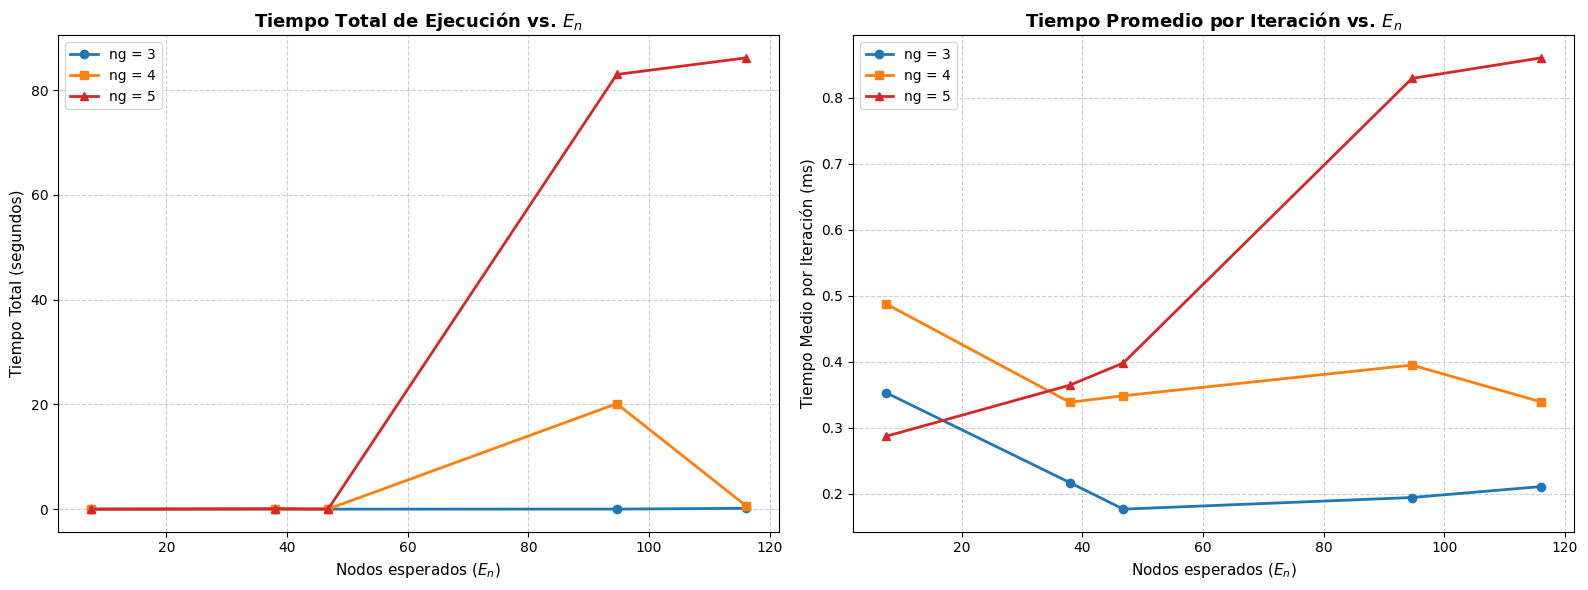

In [121]:
import matplotlib.pyplot as plt
import numpy as np

# Tus catálogos exactos proporcionados
catalogo3 = {20: {'tiempo_total': 0.004319704999943497, 'tiempo_medio_iteracion': np.float64(0.00035307119997014525)}, 1020: {'tiempo_total': 0.021275185999911628, 'tiempo_medio_iteracion': np.float64(0.00021673940000823677)}, 2020: {'tiempo_total': 0.007066604000101506, 'tiempo_medio_iteracion': np.float64(0.00017639954283887554)}, 3020: {'tiempo_total': 0.016581683999902452, 'tiempo_medio_iteracion': np.float64(0.00019404287498332452)}, 4020: {'tiempo_total': 0.169254756999635, 'tiempo_medio_iteracion': np.float64(0.00021063650251048488)}}
catalogo4 = {20: {'tiempo_total': 0.0062168290000954585, 'tiempo_medio_iteracion': np.float64(0.0004877227998804301)}, 1020: {'tiempo_total': 0.059464655999818206, 'tiempo_medio_iteracion': np.float64(0.0003384259823579829)}, 2020: {'tiempo_total': 0.022361514000294846, 'tiempo_medio_iteracion': np.float64(0.00034829885002333566)}, 3020: {'tiempo_total': 20.140279663, 'tiempo_medio_iteracion': np.float64(0.00039484416967694517)}, 4020: {'tiempo_total': 0.6970097029998215, 'tiempo_medio_iteracion': np.float64(0.00033905438950513093)}}
catalogo5 = {20: {'tiempo_total': 0.004250150999723701, 'tiempo_medio_iteracion': np.float64(0.0002867292000701127)}, 1020: {'tiempo_total': 0.0745516619999762, 'tiempo_medio_iteracion': np.float64(0.00036428688998739743)}, 2020: {'tiempo_total': 0.023268309000286536, 'tiempo_medio_iteracion': np.float64(0.00039798330909351616)}, 3020: {'tiempo_total': 83.00814264199971, 'tiempo_medio_iteracion': np.float64(0.0008292724513751217)}, 4020: {'tiempo_total': 86.17481385500014, 'tiempo_medio_iteracion': np.float64(0.0008604231089322646)}}

catalogos_por_ng = {
    3: catalogo3,
    4: catalogo4,
    5: catalogo5
}

# Valores reales de En correspondientes a los 5 índices (20, 1020, 2020, 3020, 4020)
En_valores = [7.43, 37.92, 46.80, 94.64, 116.03]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

colores = {3: 'tab:blue', 4: 'tab:orange', 5: 'tab:red'}
marcadores = {3: 'o', 4: 's', 5: '^'}

for ng, catalogo in catalogos_por_ng.items():
    keys = sorted(catalogo.keys())

    # Extraer métricas manteniendo la correspondencia exacta con los 5 puntos de En
    tiempos_totales = [catalogo[k]['tiempo_total'] for k in keys]
    tiempos_medios = [catalogo[k]['tiempo_medio_iteracion'] * 1000 for k in keys] # Convertido a ms

    # 1. Tiempo Total vs En
    ax1.plot(En_valores, tiempos_totales, marker=marcadores[ng], label=f'ng = {ng}', color=colores[ng], linewidth=2)

    # 2. Tiempo Promedio por Iteración vs En
    ax2.plot(En_valores, tiempos_medios, marker=marcadores[ng], label=f'ng = {ng}', color=colores[ng], linewidth=2)

# Estética de las gráficas
ax1.set_title("Tiempo Total de Ejecución vs. $E_n$", fontsize=13, fontweight='bold')
ax1.set_xlabel("Nodos esperados ($E_n$)", fontsize=11)
ax1.set_ylabel("Tiempo Total (segundos)", fontsize=11)
ax1.grid(True, linestyle='--', alpha=0.6)
ax1.legend()

ax2.set_title("Tiempo Promedio por Iteración vs. $E_n$", fontsize=13, fontweight='bold')
ax2.set_xlabel("Nodos esperados ($E_n$)", fontsize=11)
ax2.set_ylabel("Tiempo Medio por Iteración (ms)", fontsize=11)
ax2.grid(True, linestyle='--', alpha=0.6)
ax2.legend()

plt.tight_layout()
plt.show()

--- BENCHMARKING (N=5 grafos por ng, base n=m=100) ---

Procesando ng = 3...
ÉXITO en el paso 16: n=5, m=4
   Grafo 1/5 | En=11.8, Em=10.8 | T. medio=0.1509 ms
ÉXITO en el paso 36: n=8, m=7
   Grafo 2/5 | En=14.4, Em=13.4 | T. medio=0.1918 ms
ÉXITO en el paso 16: n=5, m=4
   Grafo 3/5 | En=10.0, Em=9.0 | T. medio=0.1687 ms
ÉXITO en el paso 382: n=24, m=22
   Grafo 4/5 | En=27.6, Em=26.6 | T. medio=0.1854 ms
ÉXITO en el paso 46: n=6, m=5
   Grafo 5/5 | En=11.8, Em=10.9 | T. medio=0.1755 ms
   📊 Promedio ng=3 -> En_avg=15.14, Em_avg=14.15 | T_avg=0.1745 ms

Procesando ng = 4...
ÉXITO en el paso 16: n=5, m=4
   Grafo 1/5 | En=11.8, Em=10.8 | T. medio=0.1608 ms
ÉXITO en el paso 36: n=8, m=7
   Grafo 2/5 | En=14.4, Em=13.4 | T. medio=0.1847 ms
ÉXITO en el paso 16: n=5, m=4
   Grafo 3/5 | En=10.0, Em=9.0 | T. medio=0.1801 ms
ÉXITO en el paso 61: n=14, m=14
   Grafo 4/5 | En=27.6, Em=26.6 | T. medio=0.2556 ms
ÉXITO en el paso 46: n=6, m=5
   Grafo 5/5 | En=11.8, Em=10.9 | T. medio=0.1773 ms
 

ValueError: 'yaxis' is not a valid value for axis; supported values are 'x', 'y', 'both'

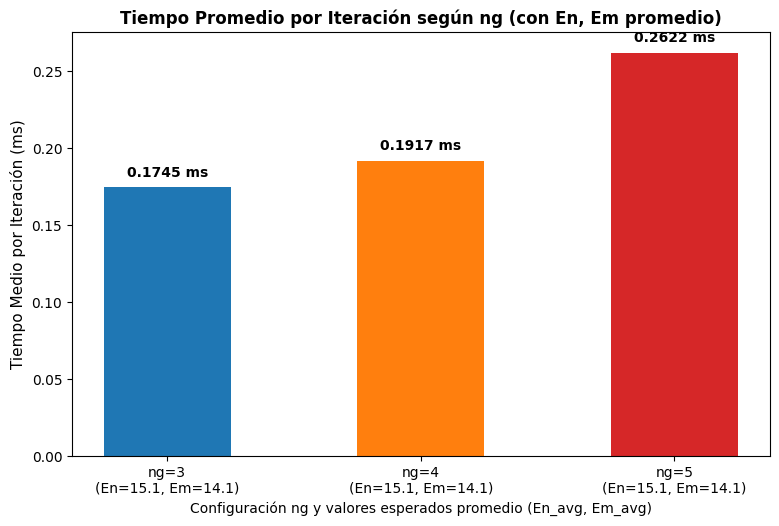

In [124]:
# ==========================================
# BENCHMARKING CON N GRAFOS POR NG
# ==========================================
valores_ng = [3, 4, 5]
N_grafos = 5       # Cantidad de grafos aleatorios por cada valor de ng
tamano_n = 100
tamano_m = 100

resultados = {}

print(f"--- BENCHMARKING (N={N_grafos} grafos por ng, base n=m={tamano_n}) ---")

for ng in valores_ng:
    tiempos_iter_ms = []
    ens = []
    ems = []

    print(f"\nProcesando ng = {ng}...")
    for i in range(N_grafos):
        semilla = 42 + i
        try:
            G_seed = generar_grafo_conexo_aleatorio(n=tamano_n, m=tamano_m, seed=semilla)
            SAMPLE = gpn.Sample(G_seed, S=1000, ng=ng, seed=semilla)

            _, _, tiempo_medio = GraphGeneratorT(
                SAMPLE, maxs=1000, node_step=5, seed=semilla, verbose=0
            )

            ens.append(SAMPLE['En'])
            ems.append(SAMPLE['Em'])
            tiempos_iter_ms.append(tiempo_medio * 1000)

            print(f"   Grafo {i+1}/{N_grafos} | En={SAMPLE['En']:.1f}, Em={SAMPLE['Em']:.1f} | T. medio={tiempo_medio*1000:.4f} ms")
        except Exception as e:
            print(f"   ⚠️ Error en ng={ng}, grafo {i+1} -> {e}")

    en_avg = np.mean(ens) if ens else 0.0
    em_avg = np.mean(ems) if ems else 0.0
    t_avg = np.mean(tiempos_iter_ms) if tiempos_iter_ms else 0.0

    resultados[ng] = {
        'En_avg': en_avg,
        'Em_avg': em_avg,
        'tiempo_avg_ms': t_avg
    }
    print(f"   📊 Promedio ng={ng} -> En_avg={en_avg:.2f}, Em_avg={em_avg:.2f} | T_avg={t_avg:.4f} ms")

# ==========================================
# GRÁFICO DE BARRAS CON EN, EM AVERAGE
# ==========================================
etiquetas_x = [
    f"ng={ng}\n(En={resultados[ng]['En_avg']:.1f}, Em={resultados[ng]['Em_avg']:.1f})"
    for ng in valores_ng
]
tiempos_promedios = [resultados[ng]['tiempo_avg_ms'] for ng in valores_ng]

fig, ax = plt.subplots(figsize=(9, 5.5))

barras = ax.bar(etiquetas_x, tiempos_promedios, color=['tab:blue', 'tab:orange', 'tab:red'], width=0.5)

for barra in barras:
    yval = barra.get_height()
    ax.text(
        barra.get_x() + barra.get_width() / 2.0,
        yval + (max(tiempos_promedios) * 0.02 if max(tiempos_promedios) > 0 else 0.01),
        f"{yval:.4f} ms",
        ha='center', va='bottom', fontsize=10, fontweight='bold'
    )

ax.set_title("Tiempo Promedio por Iteración según ng (con En, Em promedio)", fontsize=12, fontweight='bold')
ax.set_xlabel("Configuración ng y valores esperados promedio (En_avg, Em_avg)", fontsize=10)
ax.set_ylabel("Tiempo Medio por Iteración (ms)", fontsize=11)
ax.grid(True, axis='yaxis', linestyle='--', alpha=0.6)
ax.set_ylim(0, max(tiempos_promedios) * 1.15 if max(tiempos_promedios) > 0 else 1)

plt.tight_layout()
plt.show()